**1. Importações e conferência do ambiente**

In [29]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
    confusion_matrix, ConfusionMatrixDisplay, cohen_kappa_score, roc_auc_score,
)
from sklearn.tree import export_text, plot_tree

from optuna_arvore_churn import (
    verificar_suporte_categorico, criar_preprocessador, criar_pipeline,
    parametros_baseline, executar_comparacao_podas, melhor_trial_elegivel,
    avaliar_estabilidade_folds, estudar_alpha_fixo,
)

print('Scikit-learn:', verificar_suporte_categorico())
PASTA = Path('results/arvore_categorica_110')
PASTA.mkdir(parents=True, exist_ok=True)

Scikit-learn: 1.10.dev0


**2. Carregamento e divisão original 70%/30%**

In [30]:
DATASET = Path('base_churn_5000_VF2_aluno_preprocessada.xlsx')
if not DATASET.is_file():
    raise FileNotFoundError(
        f'Coloque {DATASET.name} na mesma pasta do notebook, ou ajuste DATASET.'
    )

df = pd.read_excel(DATASET)
X = df.drop(columns=['id_cliente', 'churn'])
y = df['churn'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
print('Total:', len(X), 'Treino:', len(X_train), 'Teste reservado:', len(X_test))
print('Classes no treino:', y_train.value_counts().to_dict())
print('Categorias originais:')
for coluna in ['tipo_contrato', 'forma_pagamento']:
    print(coluna, X_train[coluna].value_counts(dropna=False).to_dict())

# Importante: X_train e X_test permanecem SEM imputação prévia.

Total: 5004 Treino: 3502 Teste reservado: 1502
Classes no treino: {0: 2261, 1: 1241}
Categorias originais:
tipo_contrato {'Mensal': 1940, 'Anual': 836, 'Bienal': 709, nan: 17}
forma_pagamento {'Boleto': 1375, 'Cartão': 1206, 'Pix': 905, nan: 16}


**3. Confirmação da representação categórica nativa**

In [31]:
# Este teste usa apenas treinamento e NÃO ajusta nenhum passo em dados do teste.
pre_teste = criar_preprocessador()
X_tr_transformado = pre_teste.fit_transform(X_train)
print('Tipos depois do pré-processamento:')
print(X_tr_transformado.dtypes)
assert str(X_tr_transformado['tipo_contrato'].dtype) == 'category'
assert str(X_tr_transformado['forma_pagamento'].dtype) == 'category'

arvore_teste = criar_pipeline({'max_depth': 3})
arvore_teste.fit(X_train, y_train)
print('Máscara categórica da árvore:', arvore_teste.named_steps['arvore'].is_categorical_)
print('Treinamento com textos categóricos: OK')

Tipos depois do pré-processamento:
mensalidade_rs              float64
atrasos_6m                  float64
tipo_contrato              category
forma_pagamento            category
fibra_optica                float64
debito_automatico           float64
tempo_cliente_meses         float64
numero_chamados_total       float64
numero_chamados_30_dias     float64
numero_chamados_60_dias     float64
numero_chamados_90_dias     float64
dtype: object
Máscara categórica da árvore: [False False  True  True False False False False False False False]
Treinamento com textos categóricos: OK


**4. Subdivisão exclusiva para benchmarks individuais (56%/14% do total)**

In [32]:
X_train_exp, X_val, y_train_exp, y_val = train_test_split(
    X_train, y_train,
    test_size=0.20, random_state=42, stratify=y_train
)
# A imputação é feita pelo pipeline, após o split.
print('Treino experimental:', len(X_train_exp), 'Validação:', len(X_val))

Treino experimental: 2801 Validação: 701


**5. Benchmarks individuais dos hiperparâmetros (um de cada vez)**

Mantemos todos os parâmetros no baseline, alterando somente um por vez. Esta etapa é exploratória, não seleciona a configuração final. Na comparação de podas, usaremos um limiar comum entre as estratégias. Ajuste LIMIAR apenas com informação de treinamento/validação, antes de olhar o teste.

In [33]:
LIMIAR = 0.50  # único limiar para comparar os mecanismos de poda

def metricas_para_limiar(modelo, X_dados, y_dados, limiar):
    idx = list(modelo.named_steps['arvore'].classes_).index(1)
    prob = modelo.predict_proba(X_dados)[:, idx]
    pred = (prob >= limiar).astype(int)
    return {
        'recall': recall_score(y_dados, pred, zero_division=0),
        'precisao': precision_score(y_dados, pred, zero_division=0),
        'f1': f1_score(y_dados, pred, zero_division=0),
        'f2': fbeta_score(y_dados, pred, beta=2, zero_division=0),
        'acuracia': accuracy_score(y_dados, pred),
    }

benchmark_hiperparametros = []
grades = {
    # Hiperparâmetros inteiros
    'max_depth': [None, *range(2, 26)],
    'min_samples_split': range(2, 151, 5),
    'min_samples_leaf': range(1, 81, 3),
    'max_leaf_nodes': [None, *range(2, 151, 5)],
    # Hiperparâmetros contínuos
    'min_impurity_decrease': [
        0, 1e-6, 1e-5, 1e-4, 5e-4, 1e-3, 5e-3
    ],
    'ccp_alpha': [
        0, 1e-6, 1e-5, 1e-4, 5e-4, 1e-3, 5e-3, 2e-2
    ],
    # Hiperparâmetro categórico
    'criterion': ['gini', 'entropy'],
}

for parametro, valores in grades.items():
    for valor in valores:
        parametros = parametros_baseline()
        parametros[parametro] = valor
        modelo = criar_pipeline(parametros)
        modelo.fit(X_train_exp, y_train_exp)
        treino = metricas_para_limiar(modelo, X_train_exp, y_train_exp, LIMIAR)
        validacao = metricas_para_limiar(modelo, X_val, y_val, LIMIAR)
        arvore = modelo.named_steps['arvore']
        benchmark_hiperparametros.append({
            'hiperparametro': parametro, 'valor': str(valor),
            'recall_treino': treino['recall'], 'recall_validacao': validacao['recall'],
            'precisao_validacao': validacao['precisao'],
            'f2_validacao': validacao['f2'],
            'acuracia_treino': treino['acuracia'], 'acuracia_validacao': validacao['acuracia'],
            'gap_acuracia': treino['acuracia'] - validacao['acuracia'],
            'profundidade': arvore.get_depth(), 'folhas': arvore.get_n_leaves(),
        })

df_benchmark = pd.DataFrame(benchmark_hiperparametros)
df_benchmark.to_csv(PASTA / 'benchmark_hiperparametros.csv', index=False)
display(df_benchmark.head(10))

,hiperparametro,valor,recall_treino,recall_validacao,precisao_validacao,f2_validacao,acuracia_treino,acuracia_validacao,gap_acuracia,profundidade,folhas
0,max_depth,None,1.000000,0.504032,0.490196,0.501203,0.999643,0.639087,0.360556,24,713
1,max_depth,2,0.603223,0.596774,0.554307,0.587768,0.700464,0.687589,0.012875,2,4
2,max_depth,3,0.299094,0.266129,0.709677,0.304147,0.708318,0.701854,0.006464,3,8
3,max_depth,4,0.587110,0.500000,0.599034,0.517098,0.741878,0.704708,0.037170,4,16
4,max_depth,5,0.645519,0.560484,0.604348,0.568740,0.757230,0.714693,0.042536,5,31
5,max_depth,6,0.601208,0.516129,0.609524,0.532446,0.766155,0.711840,0.054315,6,57
6,max_depth,7,0.687815,0.536290,0.573276,0.543301,0.795073,0.694722,0.100351,7,98
7,max_depth,8,0.690836,0.544355,0.586957,0.552373,0.813281,0.703281,0.110000,8,160
8,max_depth,9,0.735146,0.504032,0.576037,0.516956,0.843627,0.693295,0.150332,9,235
9,max_depth,10,0.760322,0.508065,0.562500,0.518092,0.866833,0.686163,0.180671,10,317


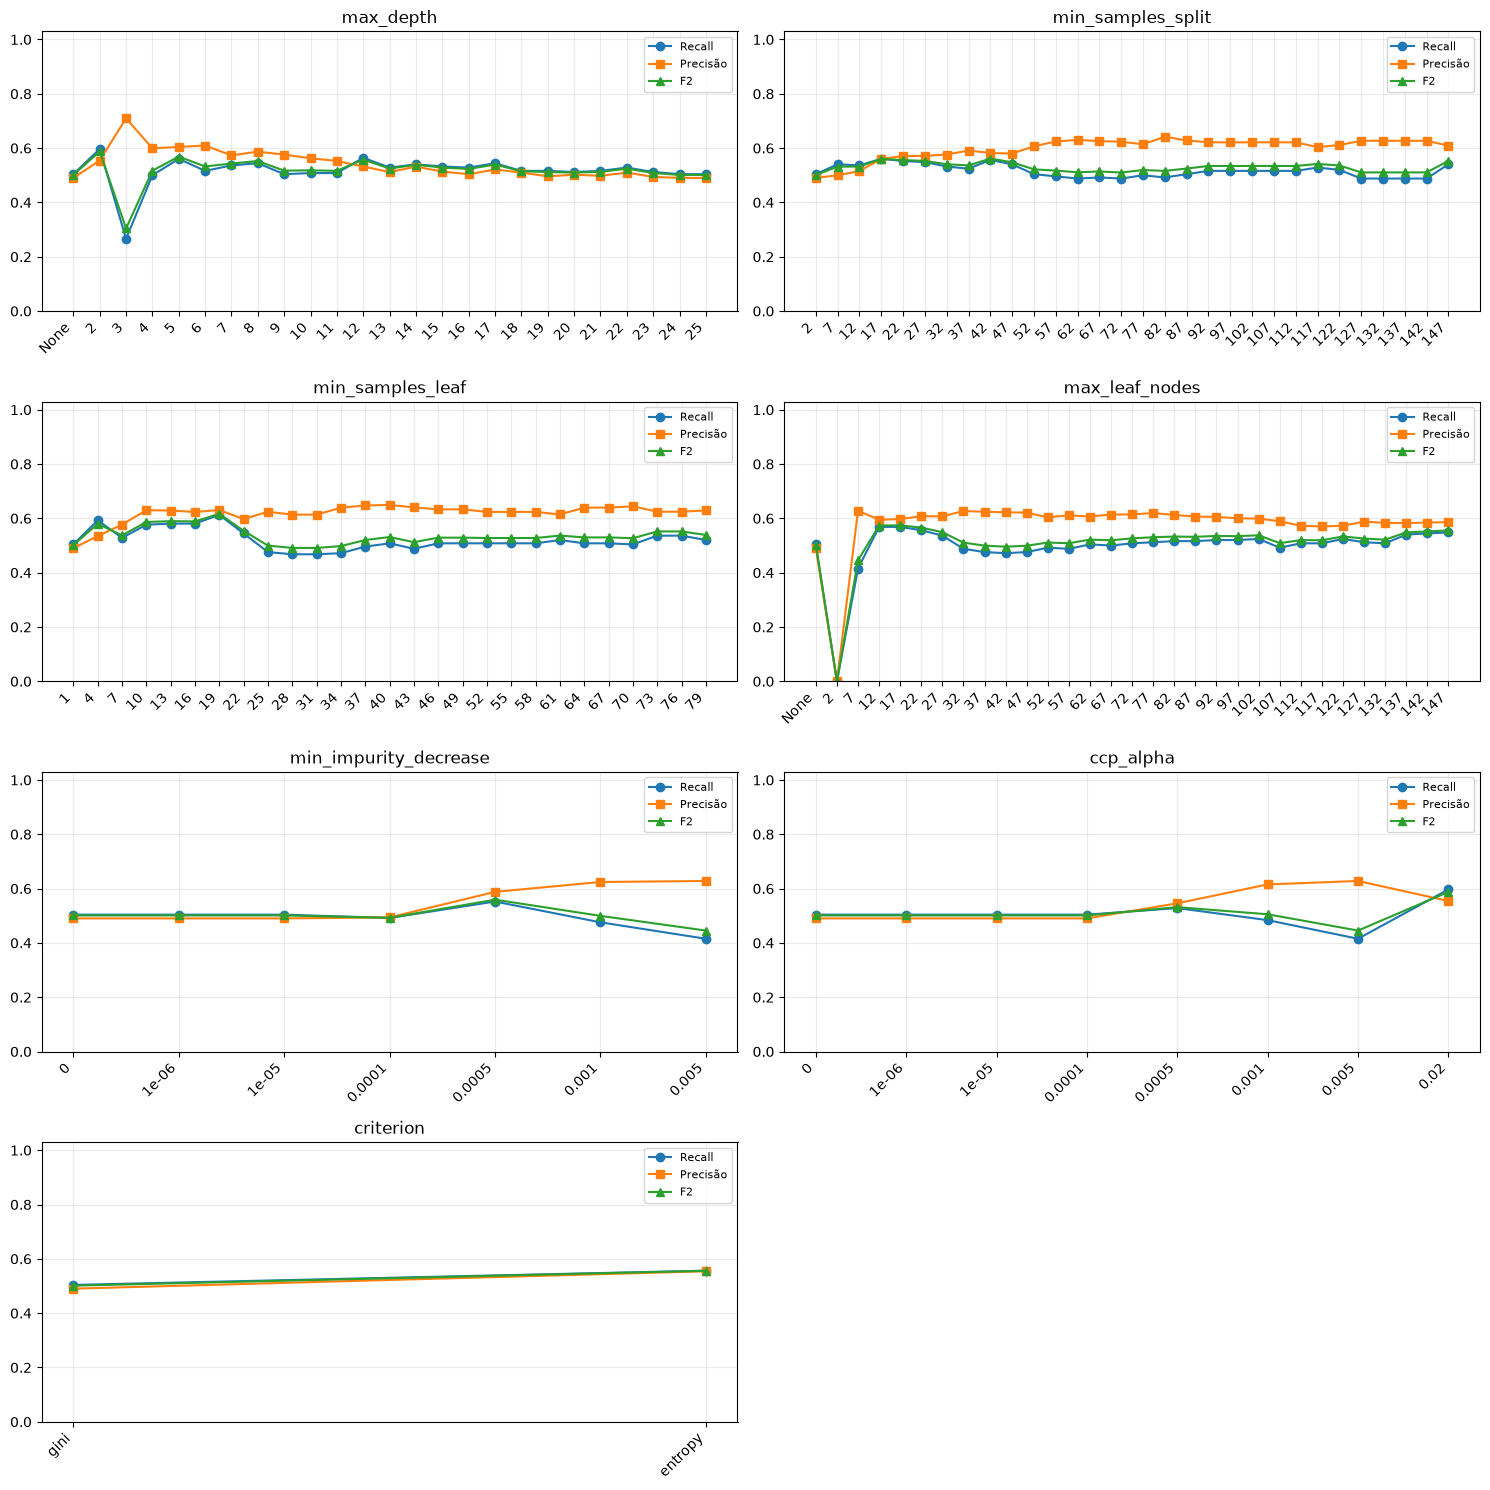

In [34]:
fig, axes = plt.subplots(4, 2, figsize=(15, 15))
for ax, (par, parte) in zip(axes.ravel(), df_benchmark.groupby('hiperparametro', sort=False)):
    eixo_x = np.arange(len(parte))
    ax.plot(eixo_x, parte['recall_validacao'], marker='o', label='Recall')
    ax.plot(eixo_x, parte['precisao_validacao'], marker='s', label='Precisão')
    ax.plot(eixo_x, parte['f2_validacao'], marker='^', label='F2')
    ax.set_xticks(eixo_x)
    ax.set_xticklabels(parte['valor'], rotation=45, ha='right')
    ax.set_ylim(0, 1.03)
    ax.set_title(par)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
for ax in list(axes.ravel())[len(grades):]:
    ax.axis('off')
plt.tight_layout()
plt.savefig(PASTA / 'benchmark_hiperparametros.png', dpi=200)
plt.show()

**6. Comparação Optuna — pré-poda, pós-poda isolada e híbrida**

As três buscas usam o mesmo criterion='gini', o mesmo splitter='best', o mesmo limiar e as mesmas cinco partições.
- Pré-poda: otimiza parâmetros que limitam o crescimento; ccp_alpha=0.
- Pós-poda isolada: usa os valores padrão de crescimento e otimiza somente ccp_alpha.
- Híbrida: permite simultaneamente limitar o crescimento e otimizar ccp_alpha.
- Baseline: árvore sem poda explícita.
Os estudos são novos e persistidos em results/arvore_categorica_110, separados dos resultados anteriores. Se alterar limiar/objetivo/dados, altere também NOME_ESTUDO.

In [35]:
# Mantenha o protocolo que você decidiu. Estes são os valores do notebook enviado.
LIMIAR = 0.20
PRECISAO_MINIMA = 0.45
OBJETIVO = 'f2_churn'  # 'recall_churn' ou 'f2_churn'
N_TRIALS = 100
N_SPLITS = 5
NOME_ESTUDO = 'E4_t020_rec_prec045_v1'

estudos, df_resumo = executar_comparacao_podas(
    X_train, y_train,
    nome_experimento=NOME_ESTUDO,
    limiar=LIMIAR,
    objetivo=OBJETIVO,
    precisao_minima=PRECISAO_MINIMA,
    n_trials=N_TRIALS,
    n_splits=N_SPLITS,
    pasta_results=PASTA,
    continuar=False,
)
colunas = ['estrategia', 'elegivel', 'recall_churn', 'precisao_churn',
           'f2_churn', 'f2_churn_dp', 'acuracia', 'profundidade', 'folhas']
display(df_resumo[[c for c in colunas if c in df_resumo.columns]].round(4))

[I 2026-11-17 15:03:49,295] Using an existing study with `study_name='E4_t020_rec_prec045_v1_pre_poda'` instead of creating a new one.
[I 2026-11-17 15:03:49,633] Using an existing study with `study_name='E4_t020_rec_prec045_v1_pos_poda'` instead of creating a new one.


E4_t020_rec_prec045_v1_pre_poda: reutilizando 100 trials existentes
E4_t020_rec_prec045_v1_pre_poda: recall=0.8936, precisao=0.4642, F2=0.7538


[I 2026-11-17 15:03:49,918] Using an existing study with `study_name='E4_t020_rec_prec045_v1_hibrida'` instead of creating a new one.


E4_t020_rec_prec045_v1_pos_poda: reutilizando 100 trials existentes
E4_t020_rec_prec045_v1_pos_poda: recall=0.8493, precisao=0.4945, F2=0.7417
E4_t020_rec_prec045_v1_hibrida: reutilizando 100 trials existentes
E4_t020_rec_prec045_v1_hibrida: recall=0.8936, precisao=0.4642, F2=0.7538


,estrategia,elegivel,recall_churn,precisao_churn,f2_churn,f2_churn_dp,acuracia,profundidade,folhas
0,baseline,True,0.5447,0.5124,0.5379,0.0079,0.6548,21.0,688.8
1,pre_poda,True,0.8936,0.4642,0.7538,0.0156,0.5959,6.6,24.2
2,pos_poda,True,0.8493,0.4945,0.7417,0.0143,0.6368,8.0,25.6
3,hibrida,True,0.8936,0.4642,0.7538,0.0156,0.5959,6.8,25.2


6.1. Recuperar os estudos após reiniciar o kernel (sem refazer o Optuna)

In [37]:
# Célula opcional — útil após reiniciar o kernel.
# Se você acabou de executar a seção 6, não precisa executá-la.
import optuna

NOME_ESTUDO = 'E3_t020_rec_prec040_v1'  # use o nome da seção 6
storage = f"sqlite:///{(PASTA / 'estudos_optuna_categorico.db').resolve().as_posix()}"
estudos = {
    estrategia: optuna.load_study(
        study_name=f"{NOME_ESTUDO}_{estrategia}",
        storage=storage,
    )
    for estrategia in ['pre_poda', 'pos_poda', 'hibrida']
}
# A tabela do baseline e das estratégias também fica salva em CSV.
df_resumo = pd.read_csv(PASTA / f'resumo_{NOME_ESTUDO}.csv')
# Recuperar junto o protocolo do experimento (evita usar o LIMIAR do benchmark).
attrs = next(iter(estudos.values())).user_attrs
LIMIAR = float(attrs['limiar'])
PRECISAO_MINIMA = attrs.get('precisao_minima')
N_SPLITS = int(attrs['n_splits'])
OBJETIVO = attrs['objetivo']
print('Protocolo recuperado:', {'limiar': LIMIAR, 'objetivo': OBJETIVO,
                                 'precisao_minima': PRECISAO_MINIMA, 'folds': N_SPLITS})
print({estrategia: len(estudo.trials) for estrategia, estudo in estudos.items()})

Protocolo recuperado: {'limiar': 0.2, 'objetivo': 'recall_churn', 'precisao_minima': 0.4, 'folds': 5}
{'pre_poda': 100, 'pos_poda': 100, 'hibrida': 100}


**7. Selecionar os melhores por recall e por F2 — primeira validação**

In [59]:
from optuna.trial import TrialState

# Limiar persistido no Optuna. Mantém o valor correto mesmo se a variável
# LIMIAR tiver sido alterada em outra célula (benchmark, curva de limiares etc.).
limiares_salvos = {nome: float(estudo.user_attrs['limiar'])
                   for nome, estudo in estudos.items()}
if len(set(limiares_salvos.values())) != 1:
    raise ValueError(f'Os estudos possuem limiares diferentes: {limiares_salvos}')
LIMIAR_ESTUDO = next(iter(limiares_salvos.values()))


# A tabela de seleção também permite comparar os resultados da CV original.
if 'df_resumo' not in globals():
    df_resumo = pd.read_csv(PASTA / f'resumo_{NOME_ESTUDO}.csv')

candidatos_duas_metricas = {
    'baseline': {
        'parametros': parametros_baseline(),
        'limiar': LIMIAR_ESTUDO,
    }
}

linha_base = df_resumo.loc[df_resumo['estrategia'] == 'baseline'].iloc[0]
linhas_primeira_cv = [{
    'modelo': 'baseline',
    'estrategia': 'baseline',
    'criterio_selecao': 'referência',
    'trial': np.nan,
    'limiar': LIMIAR_ESTUDO,
    'recall_cv1': float(linha_base['recall_churn']),
    'f2_cv1': float(linha_base['f2_churn']),
    'precisao_cv1': float(linha_base['precisao_churn']),
}]

for estrategia, estudo in estudos.items():
    trials_elegiveis = [
        t for t in estudo.trials
        if t.state == TrialState.COMPLETE
        and t.value is not None
        and t.user_attrs.get('elegivel', False)
        and 'parametros_arvore' in t.user_attrs
    ]
    if not trials_elegiveis:
        print(f'{estrategia}: nenhum trial elegível. Estratégia ignorada.')
        continue

    for metrica, sufixo in [('recall_churn', 'recall'), ('f2_churn', 'f2')]:
        melhor = max(
            trials_elegiveis,
            key=lambda t: (
                float(t.user_attrs[metrica]),
                float(t.user_attrs['precisao_churn']),
                -float(t.user_attrs.get('folhas', np.inf)),
            ),
        )
        nome_modelo = f'{estrategia}_{sufixo}'
        candidatos_duas_metricas[nome_modelo] = {
            'parametros': dict(melhor.user_attrs['parametros_arvore']),
            'limiar': LIMIAR_ESTUDO,
        }
        linhas_primeira_cv.append({
            'modelo': nome_modelo,
            'estrategia': estrategia,
            'criterio_selecao': metrica,
            'trial': melhor.number,
            'limiar': LIMIAR_ESTUDO,
            'recall_cv1': float(melhor.user_attrs['recall_churn']),
            'f2_cv1': float(melhor.user_attrs['f2_churn']),
            'precisao_cv1': float(melhor.user_attrs['precisao_churn']),
        })

# Nomes internos permanecem estáveis (úteis para carregar candidatos e CSVs).
# Os rótulos descritivos são usados nas tabelas, gráficos e matrizes.
def rotulo_modelo(nome, curto=False):
    nomes = {
        'baseline': 'Baseline (sem poda)',
        'pre_poda': 'Pré-poda isolada',
        'pos_poda': 'Pós-poda isolada',
        'hibrida': 'Poda híbrida (pré + pós)',
    }
    if nome not in candidatos_duas_metricas:
        raise KeyError(f'Candidato desconhecido: {nome}')
    config = candidatos_duas_metricas[nome]
    limiar = float(config['limiar'])
    if nome == 'baseline':
        estrategia, criterio = 'baseline', 'Referência'
    else:
        estrategia, sufixo = nome.rsplit('_', 1)
        criterio = {'recall': 'Melhor recall', 'f2': 'Melhor F2'}[sufixo]
    base = f'{nomes[estrategia]} · {criterio} · limiar={limiar:.2f}'
    if curto:
        return base
    trial = config.get('trial')
    return base + (f' · trial #{trial}' if trial is not None else '')

# Primeiro salvar os metadados, depois montar os rótulos com o número do trial.
for linha in linhas_primeira_cv:
    nome = linha['modelo']
    candidatos_duas_metricas[nome]['criterio_selecao'] = linha['criterio_selecao']
    candidatos_duas_metricas[nome]['trial'] = (
        None if pd.isna(linha['trial']) else int(linha['trial'])
    )
    linha['rotulo'] = rotulo_modelo(nome)
    # As configurações foram selecionadas no Optuna usando CV1.
    linha['limiar'] = float(candidatos_duas_metricas[nome]['limiar'])

df_primeira_cv = pd.DataFrame(linhas_primeira_cv)
ordem_colunas = ['modelo', 'rotulo', 'limiar', 'estrategia',
                 'criterio_selecao', 'trial', 'recall_cv1',
                 'f2_cv1', 'precisao_cv1']
df_primeira_cv = df_primeira_cv[ordem_colunas]
df_primeira_cv.to_csv(PASTA / 'candidatos_recall_f2_cv1.csv', index=False)
display(df_primeira_cv.round(4))
print(f'Limiar do estudo recuperado do Optuna: {LIMIAR_ESTUDO:.2f} '
      '(igual para todos os candidatos; comparação controlada).')

,modelo,rotulo,limiar,estrategia,criterio_selecao,trial,recall_cv1,f2_cv1,precisao_cv1
0,baseline,Baseline (sem poda) · Referência · limiar=0.20,0.2,baseline,referência,NaN,0.5447,0.5379,0.5124
1,pre_poda_recall,Pré-poda isolada · Melhor recall · limiar=0.20...,0.2,pre_poda,recall_churn,64.0,0.8960,0.7517,0.4577
2,pre_poda_f2,Pré-poda isolada · Melhor F2 · limiar=0.20 · t...,0.2,pre_poda,f2_churn,13.0,0.8936,0.7538,0.4642
3,pos_poda_recall,Pós-poda isolada · Melhor recall · limiar=0.20...,0.2,pos_poda,recall_churn,52.0,0.9169,0.7291,0.4110
4,pos_poda_f2,Pós-poda isolada · Melhor F2 · limiar=0.20 · t...,0.2,pos_poda,f2_churn,9.0,0.8517,0.7414,0.4903
5,hibrida_recall,Poda híbrida (pré + pós) · Melhor recall · lim...,0.2,hibrida,recall_churn,58.0,0.8960,0.7517,0.4577
6,hibrida_f2,Poda híbrida (pré + pós) · Melhor F2 · limiar=...,0.2,hibrida,f2_churn,77.0,0.8944,0.7545,0.4646


Limiar do estudo recuperado do Optuna: 0.20 (igual para todos os candidatos; comparação controlada).


**8. Segunda validação cruzada — comparação dos candidatos selecionados**

Avaliamos os candidatos da seção 7 em cinco novos folds estratificados (semente 2026), usando somente X_train e y_train. Todos recebem o mesmo limiar; o KNN é ajustado somente no treino de cada fold e as colunas continuam com dtype categórico nativo.

Esta segunda CV mede a sensibilidade dos candidatos a outras divisões, mas não é um teste independente: as amostras já participaram da busca de hiperparâmetros da primeira CV. O conjunto de teste reservado (X_test, y_test) permanece intocado.

In [60]:
from sklearn.tree import DecisionTreeClassifier

SEMENTE_CV2 = 2026
cv2 = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEMENTE_CV2)
linhas_cv2 = []
linhas_oof_cv2 = []

for fold, (ind_tr, ind_val) in enumerate(cv2.split(X_train, y_train), start=1):
    X_tr, X_valid = X_train.iloc[ind_tr], X_train.iloc[ind_val]
    y_tr, y_valid = y_train.iloc[ind_tr], y_train.iloc[ind_val]

    # Pré-processamento sem vazamento, APENAS no treino do fold.
    # Como não depende de y, pode ser reutilizado entre modelos nesse fold.
    pre = criar_preprocessador()
    X_tr_proc = pre.fit_transform(X_tr)
    X_valid_proc = pre.transform(X_valid)

    for nome, configuracao in candidatos_duas_metricas.items():
        params = dict(configuracao['parametros'])
        params.pop('random_state', None)
        params.pop('categorical_features', None)
        arvore = DecisionTreeClassifier(
            categorical_features='from_dtype', random_state=42, **params
        )
        arvore.fit(X_tr_proc, y_tr)
        prob = arvore.predict_proba(X_valid_proc)[:, list(arvore.classes_).index(1)]
        pred = (prob >= configuracao['limiar']).astype(int)
        # Guarda a previsão individual de cada observação APENAS no fold
        # de validação. Isso permite gerar matrizes OOF sem refazer os treinos.
        for pos, real, previsto, proba in zip(
            ind_val, y_valid.to_numpy(), pred, prob
        ):
            linhas_oof_cv2.append({
                'modelo': nome,
                'fold': fold,
                'posicao_treino': int(pos),
                'y_real': int(real),
                'y_pred': int(previsto),
                'prob_churn': float(proba),
                'limiar': float(configuracao['limiar']),
            })
        linhas_cv2.append({
            'modelo': nome, 'rotulo': rotulo_modelo(nome),
            'limiar': float(configuracao['limiar']), 'fold': fold,
            'recall': recall_score(y_valid, pred, zero_division=0),
            'precisao': precision_score(y_valid, pred, zero_division=0),
            'f2': fbeta_score(y_valid, pred, beta=2, zero_division=0),
            'f1': f1_score(y_valid, pred, zero_division=0),
            'acuracia': accuracy_score(y_valid, pred),
            'profundidade': arvore.get_depth(),
            'folhas': arvore.get_n_leaves(),
            'nos': arvore.tree_.node_count,
        })

df_cv2_folds = pd.DataFrame(linhas_cv2)
df_cv2_oof = pd.DataFrame(linhas_oof_cv2)
# Armazenar predições evita refazer a validação só para montar as matrizes.
df_cv2_oof.to_csv(PASTA / 'predicoes_oof_segunda_validacao.csv', index=False)
df_cv2_resumo = df_cv2_folds.groupby('modelo', as_index=False).agg(
    recall_cv2=('recall', 'mean'), recall_dp=('recall', 'std'),
    f2_cv2=('f2', 'mean'), f2_dp=('f2', 'std'),
    precisao_cv2=('precisao', 'mean'), precisao_dp=('precisao', 'std'),
    f1_cv2=('f1', 'mean'), acuracia_cv2=('acuracia', 'mean'),
    profundidade_media=('profundidade', 'mean'),
    folhas_medias=('folhas', 'mean'), nos_medios=('nos', 'mean'),
    folds_com_precisao_minima=('precisao', lambda s: int((s >= PRECISAO_MINIMA).sum())),
)

df_comparacao_cv1_cv2 = df_primeira_cv.merge(df_cv2_resumo, on='modelo', how='left')
df_cv2_folds.to_csv(PASTA / 'segunda_validacao_por_fold.csv', index=False)
df_comparacao_cv1_cv2.to_csv(PASTA / 'comparacao_primeira_segunda_validacao.csv', index=False)

colunas_mostrar = [
    'modelo', 'rotulo', 'limiar', 'trial', 'recall_cv1', 'recall_cv2', 'recall_dp',
    'f2_cv1', 'f2_cv2', 'f2_dp', 'precisao_cv1', 'precisao_cv2',
    'folds_com_precisao_minima', 'nos_medios', 'profundidade_media',
]
display(df_comparacao_cv1_cv2[colunas_mostrar].round(4))

,modelo,rotulo,limiar,trial,recall_cv1,recall_cv2,recall_dp,f2_cv1,f2_cv2,f2_dp,precisao_cv1,precisao_cv2,folds_com_precisao_minima,nos_medios,profundidade_media
0,baseline,Baseline (sem poda) · Referência · limiar=0.20,0.2,NaN,0.5447,0.5528,0.0604,0.5379,0.5481,0.0525,0.5124,0.5315,5,1419.0,22.4
1,pre_poda_recall,Pré-poda isolada · Melhor recall · limiar=0.20...,0.2,64.0,0.8960,0.9001,0.0211,0.7517,0.7558,0.0118,0.4577,0.4609,5,53.4,6.8
2,pre_poda_f2,Pré-poda isolada · Melhor F2 · limiar=0.20 · t...,0.2,13.0,0.8936,0.9081,0.0262,0.7538,0.7608,0.0111,0.4642,0.4623,5,44.2,6.2
3,pos_poda_recall,Pós-poda isolada · Melhor recall · limiar=0.20...,0.2,52.0,0.9169,0.9274,0.0994,0.7291,0.7236,0.0131,0.4110,0.3977,2,7.4,2.8
4,pos_poda_f2,Pós-poda isolada · Melhor F2 · limiar=0.20 · t...,0.2,9.0,0.8517,0.8686,0.0373,0.7414,0.7469,0.0206,0.4903,0.4801,5,43.8,6.4
5,hibrida_recall,Poda híbrida (pré + pós) · Melhor recall · lim...,0.2,58.0,0.8960,0.9001,0.0211,0.7517,0.7558,0.0118,0.4577,0.4609,5,53.4,6.8
6,hibrida_f2,Poda híbrida (pré + pós) · Melhor F2 · limiar=...,0.2,77.0,0.8944,0.8984,0.0207,0.7545,0.7562,0.0116,0.4646,0.4631,5,49.0,6.8


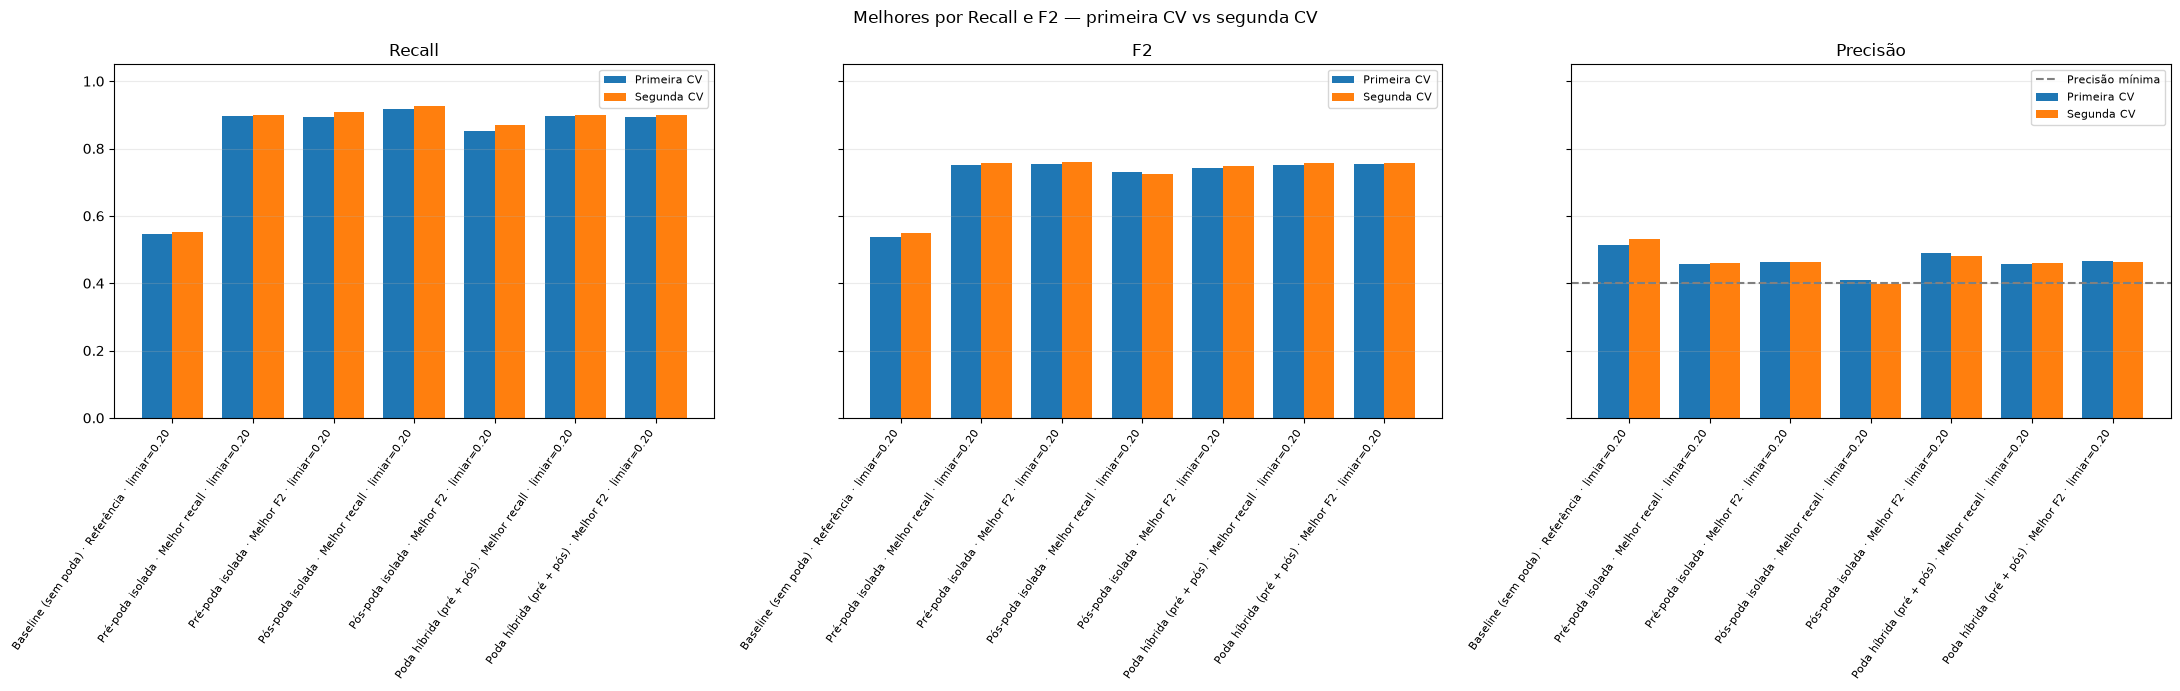

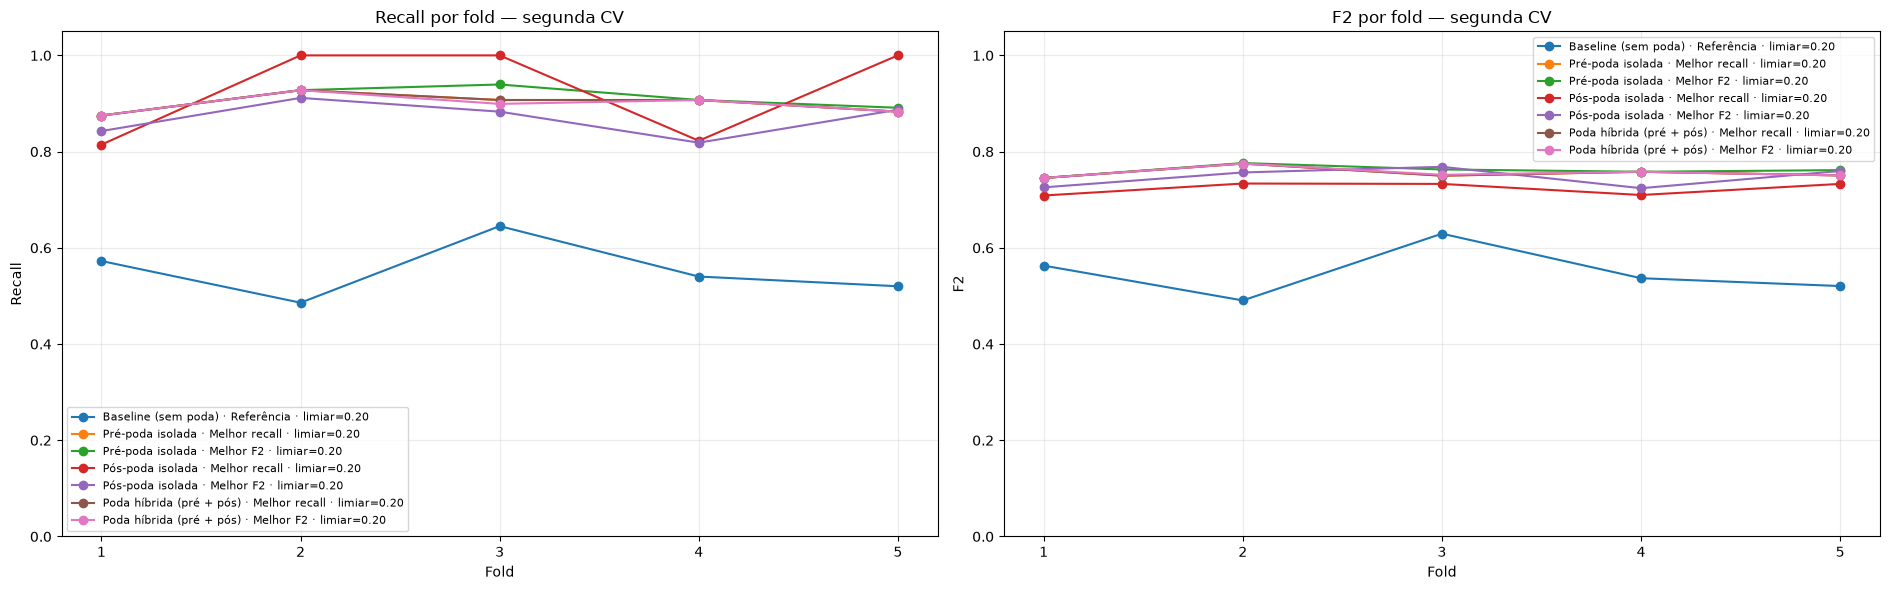

In [61]:
# Gráfico A: métricas da primeira CV x segunda CV, por candidato.
# Recuperar a tabela previamente salva, se a segunda CV não estiver em memória.
if 'df_comparacao_cv1_cv2' not in globals():
    df_comparacao_cv1_cv2 = pd.read_csv(
        PASTA / 'comparacao_primeira_segunda_validacao.csv'
    )
# Atualizar rótulos e limiares mesmo quando o CSV foi criado pela versão antiga.
df_comparacao_cv1_cv2['rotulo'] = df_comparacao_cv1_cv2['modelo'].map(rotulo_modelo)
df_comparacao_cv1_cv2['limiar'] = df_comparacao_cv1_cv2['modelo'].map(
    lambda nome: float(candidatos_duas_metricas[nome]['limiar'])
)
comparacao = df_comparacao_cv1_cv2.reset_index(drop=True)
nomes = [rotulo_modelo(nome, curto=True) for nome in comparacao['modelo']]
x = np.arange(len(nomes))
fig, axs = plt.subplots(1, 3, figsize=(22, 7), sharey=True)

for ax, (legenda, m1, m2) in zip(axs, [
    ('Recall', 'recall_cv1', 'recall_cv2'),
    ('F2', 'f2_cv1', 'f2_cv2'),
    ('Precisão', 'precisao_cv1', 'precisao_cv2'),
]):
    ax.bar(x - 0.19, comparacao[m1], width=0.38, label='Primeira CV')
    ax.bar(x + 0.19, comparacao[m2], width=0.38, label='Segunda CV')
    if legenda == 'Precisão':
        ax.axhline(PRECISAO_MINIMA, ls='--', color='gray', label='Precisão mínima')
    ax.set_title(legenda)
    ax.set_xticks(x)
    ax.set_xticklabels(nomes, rotation=55, ha='right', fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.grid(axis='y', alpha=0.25)
    ax.legend(fontsize=8, loc='best')
fig.suptitle('Melhores por Recall e F2 — primeira CV vs segunda CV')
plt.tight_layout()
plt.savefig(PASTA / 'melhores_cv1_vs_cv2.png', dpi=200, bbox_inches='tight')
plt.show()

# Gráfico B: dispersão/estabilidade de recall e F2 nos novos folds.
if 'df_cv2_folds' not in globals():
    df_cv2_folds = pd.read_csv(PASTA / 'segunda_validacao_por_fold.csv')
fig, axs = plt.subplots(1, 2, figsize=(19, 6))
for nome, parte in df_cv2_folds.groupby('modelo', sort=False):
    axs[0].plot(parte['fold'], parte['recall'], marker='o', label=rotulo_modelo(nome, curto=True))
    axs[1].plot(parte['fold'], parte['f2'], marker='o', label=rotulo_modelo(nome, curto=True))
for ax, metrica in zip(axs, ['Recall', 'F2']):
    ax.set(title=f'{metrica} por fold — segunda CV', xlabel='Fold', ylabel=metrica)
    ax.set_xticks(range(1, N_SPLITS + 1))
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, loc='best')
plt.tight_layout()
plt.savefig(PASTA / 'melhores_segunda_cv_folds.png', dpi=200, bbox_inches='tight')
plt.show()

**8.1. Matrizes de confusão dos melhores por recall e F2 — segunda validação (OOF)**

As matrizes abaixo não usam os 30% de teste. As previsões out-of-fold são as mesmas da seção 8: cada cliente foi previsto por uma árvore que não o utilizou no próprio treinamento daquele fold. Não executamos o Optuna novamente.

Mostramos: maior recall sem restrição (para verificar situações em que todos são previstos como churn), melhor recall com precisão mínima e melhor F2 com precisão mínima. Se dois critérios escolherem a mesma configuração, a matriz aparece uma única vez. Exibimos também as matrizes de todos os candidatos da segunda CV para comparação.

A precisão mínima é aplicada à média dos cinco folds, como no Optuna. A precisão agregada dos OOF pode diferir ligeiramente dessa média. Essa análise é diagnóstica; a segunda CV reutiliza observações empregadas na seleção do Optuna e não equivale a uma validação completamente independente.

Seleção pela MÉDIA das métricas nos 5 folds:
Maior recall (sem restrição): Pós-poda isolada · Melhor recall · limiar=0.20 · trial #52 | recall=0.927 | F2=0.724 | precisão=0.398
Maior recall (precisão mínima): Pré-poda isolada · Melhor F2 · limiar=0.20 · trial #13 | recall=0.908 | F2=0.761 | precisão=0.462
Maior F2 (precisão mínima): Pré-poda isolada · Melhor F2 · limiar=0.20 · trial #13 | recall=0.908 | F2=0.761 | precisão=0.462


,modelo,rotulo,limiar,TN,FP,FN,TP,recall_oof,precisao_oof,f2_oof,acuracia_oof,percentual_previsto_churn,recall_cv2,f2_cv2,precisao_cv2
0,baseline,Baseline (sem poda) · Referência · limiar=0.20,0.2,1659,602,555,686,0.5528,0.5326,0.5486,0.6696,0.3678,0.5528,0.5481,0.5315
1,pre_poda_recall,Pré-poda isolada · Melhor recall · limiar=0.20...,0.2,953,1308,124,1117,0.9001,0.4606,0.7559,0.5911,0.6925,0.9001,0.7558,0.4609
2,pre_poda_f2,Pré-poda isolada · Melhor F2 · limiar=0.20 · t...,0.2,946,1315,114,1127,0.9081,0.4615,0.7609,0.5919,0.6973,0.9081,0.7608,0.4623
3,pos_poda_recall,Pós-poda isolada · Melhor recall · limiar=0.20...,0.2,433,1828,90,1151,0.9275,0.3864,0.7245,0.4523,0.8507,0.9274,0.7236,0.3977
4,pos_poda_f2,Pós-poda isolada · Melhor F2 · limiar=0.20 · t...,0.2,1088,1173,163,1078,0.8687,0.4789,0.7471,0.6185,0.6428,0.8686,0.7469,0.4801
5,hibrida_recall,Poda híbrida (pré + pós) · Melhor recall · lim...,0.2,953,1308,124,1117,0.9001,0.4606,0.7559,0.5911,0.6925,0.9001,0.7558,0.4609
6,hibrida_f2,Poda híbrida (pré + pós) · Melhor F2 · limiar=...,0.2,968,1293,126,1115,0.8985,0.4630,0.7562,0.5948,0.6876,0.8984,0.7562,0.4631


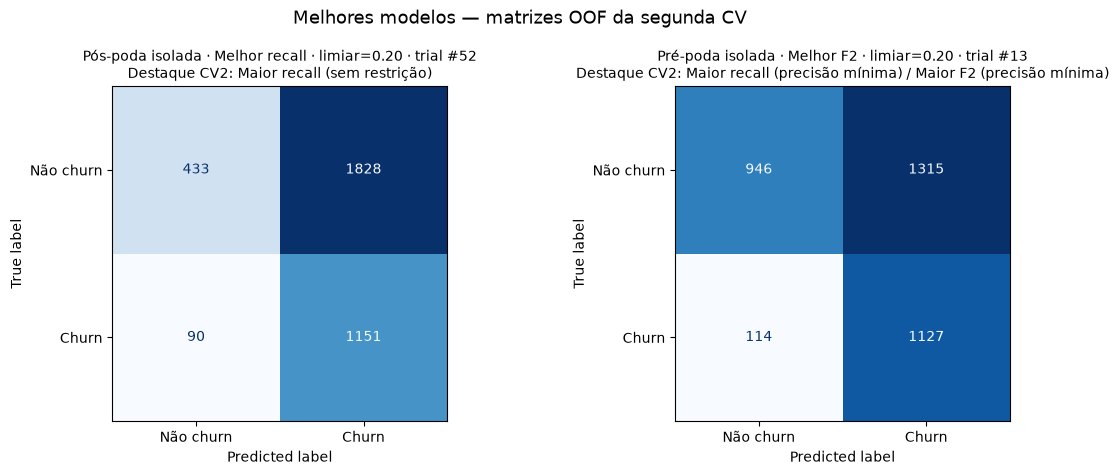

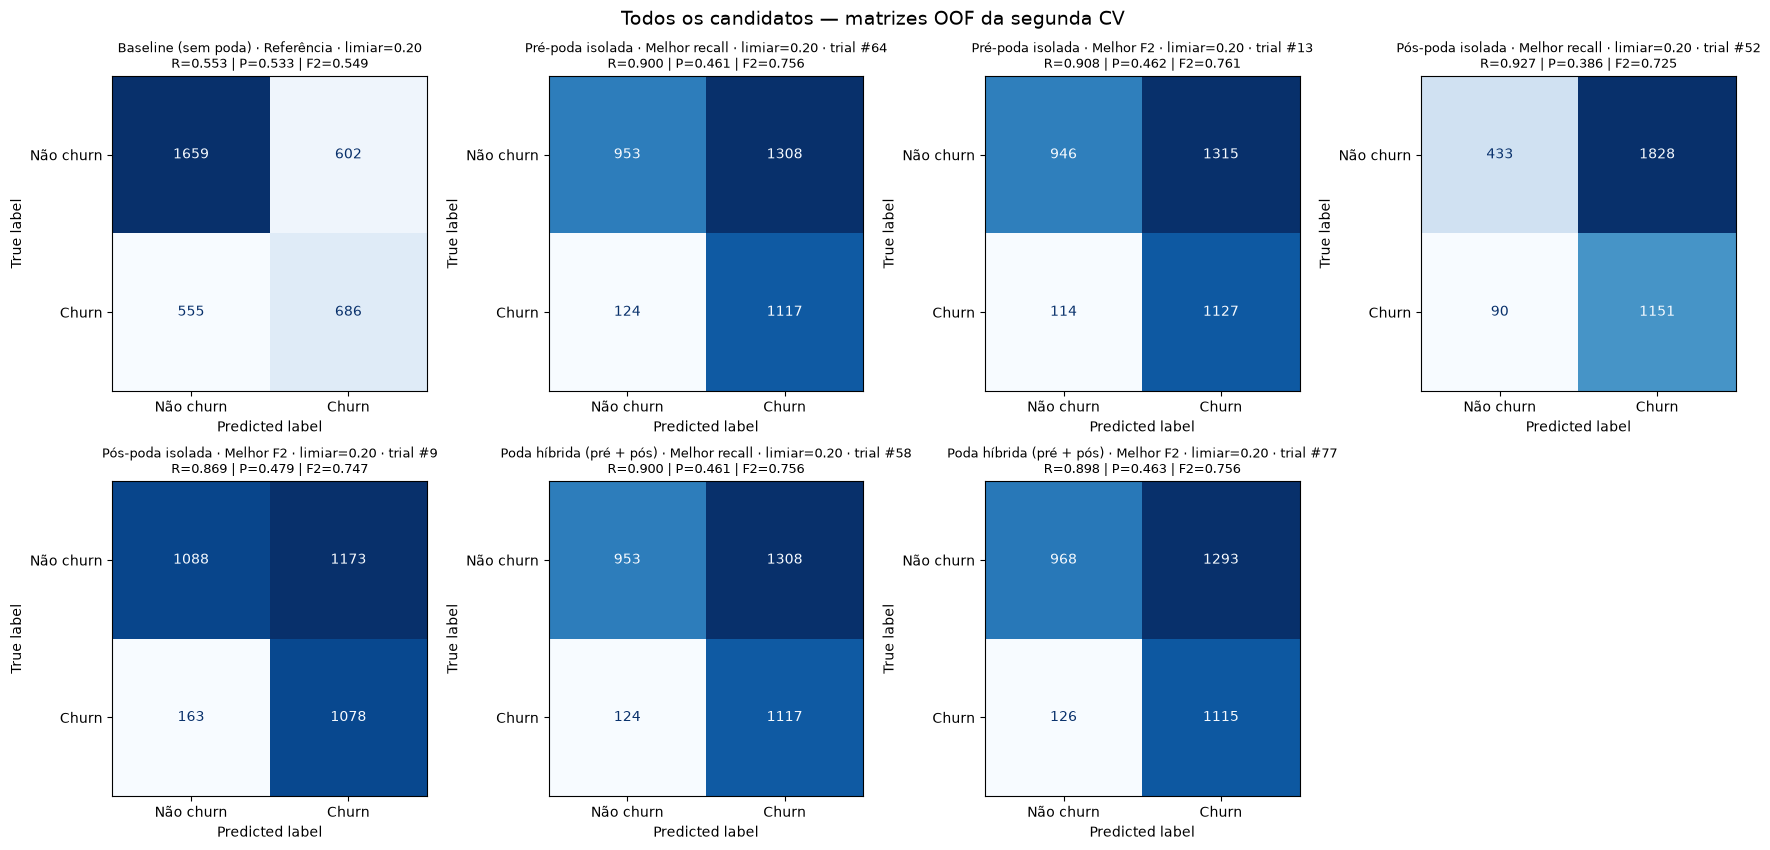

In [62]:
# As previsões são guardadas na seção 8 para não reexecutar o Optuna nem
# treinar novamente os modelos ao montar as matrizes desta seção.
caminho_oof = PASTA / 'predicoes_oof_segunda_validacao.csv'
if 'df_cv2_oof' not in globals():
    if not caminho_oof.exists():
        raise FileNotFoundError(
            'Execute a seção 8 uma vez (a versão atualizada salva as '
            'predições OOF) ou recupere o CSV existente.'
        )
    df_cv2_oof = pd.read_csv(caminho_oof)

if 'df_cv2_resumo' not in globals():
    if 'df_cv2_folds' not in globals():
        df_cv2_folds = pd.read_csv(PASTA / 'segunda_validacao_por_fold.csv')
    df_cv2_resumo = df_cv2_folds.groupby('modelo', as_index=False).agg(
        recall_cv2=('recall', 'mean'), f2_cv2=('f2', 'mean'),
        precisao_cv2=('precisao', 'mean'),
    )

colunas_esperadas = {'modelo', 'fold', 'posicao_treino', 'y_real', 'y_pred'}
if not colunas_esperadas.issubset(df_cv2_oof.columns):
    raise ValueError('CSV de predições OOF está incompleto; execute novamente a seção 8.')

# Cada cliente do conjunto de treino deve aparecer exatamente uma vez por modelo.
for nome, parte in df_cv2_oof.groupby('modelo'):
    posicoes = parte['posicao_treino'].to_numpy(dtype=int)
    if (len(parte) != len(X_train) or len(set(posicoes)) != len(X_train)
            or set(posicoes) != set(range(len(X_train)))):
        raise ValueError(f'Predições OOF incompletas ou duplicadas: {nome}')
    if not np.array_equal(
        parte['y_real'].to_numpy(dtype=int),
        y_train.iloc[posicoes].to_numpy(dtype=int)
    ):
        raise ValueError(f'O CSV OOF não corresponde ao treino atual: {nome}')

ranking_cv2 = df_cv2_resumo.copy()
ranking_cv2 = ranking_cv2.sort_values(
    ['recall_cv2', 'f2_cv2', 'precisao_cv2'], ascending=False
)
melhor_recall_livre = ranking_cv2.iloc[0]['modelo']

if PRECISAO_MINIMA is None:
    ranking_elegivel = df_cv2_resumo.copy()
else:
    ranking_elegivel = df_cv2_resumo[
        df_cv2_resumo['precisao_cv2'] >= PRECISAO_MINIMA
    ].copy()

MODELOS_DESTAQUE_CV2 = {'Maior recall (sem restrição)': melhor_recall_livre}
if ranking_elegivel.empty:
    print('AVISO: nenhum candidato mantém a precisão média mínima na segunda CV.')
    print('As matrizes abaixo são apenas diagnósticas, sem candidato elegível.')
else:
    melhor_recall_elegivel = ranking_elegivel.sort_values(
        ['recall_cv2', 'f2_cv2', 'precisao_cv2'], ascending=False
    ).iloc[0]['modelo']
    melhor_f2_elegivel = ranking_elegivel.sort_values(
        ['f2_cv2', 'recall_cv2', 'precisao_cv2'], ascending=False
    ).iloc[0]['modelo']
    MODELOS_DESTAQUE_CV2['Maior recall (precisão mínima)'] = melhor_recall_elegivel
    MODELOS_DESTAQUE_CV2['Maior F2 (precisão mínima)'] = melhor_f2_elegivel

print('Seleção pela MÉDIA das métricas nos 5 folds:')
for criterio, nome in MODELOS_DESTAQUE_CV2.items():
    linha = df_cv2_resumo.set_index('modelo').loc[nome]
    print(f'{criterio}: {rotulo_modelo(nome)} | recall={linha["recall_cv2"]:.3f} | '
          f'F2={linha["f2_cv2"]:.3f} | precisão={linha["precisao_cv2"]:.3f}')

# Matriz e métricas agregadas de todas as predições OOF.
def extrair_resumo_matriz(y_real, y_previsto, nome):
    tn, fp, fn, tp = confusion_matrix(y_real, y_previsto, labels=[0, 1]).ravel()
    return {
        'modelo': nome, 'TN': int(tn), 'FP': int(fp),
        'FN': int(fn), 'TP': int(tp),
        'recall_oof': recall_score(y_real, y_previsto, zero_division=0),
        'precisao_oof': precision_score(y_real, y_previsto, zero_division=0),
        'f2_oof': fbeta_score(y_real, y_previsto, beta=2, zero_division=0),
        'acuracia_oof': accuracy_score(y_real, y_previsto),
        'percentual_previsto_churn': float(np.mean(np.asarray(y_previsto) == 1)),
    }

tabela_oof = pd.DataFrame([
    extrair_resumo_matriz(grupo['y_real'], grupo['y_pred'], nome)
    for nome, grupo in df_cv2_oof.groupby('modelo', sort=False)
])
tabela_oof['rotulo'] = tabela_oof['modelo'].map(lambda nome: rotulo_modelo(nome))
tabela_oof['limiar'] = tabela_oof['modelo'].map(
    lambda nome: float(candidatos_duas_metricas[nome]['limiar'])
)
tabela_oof = tabela_oof.merge(
    df_cv2_resumo[['modelo', 'recall_cv2', 'f2_cv2', 'precisao_cv2']],
    on='modelo', how='left'
)
tabela_oof.to_csv(PASTA / 'matrizes_oof_metricas.csv', index=False)
cols_oof = ['modelo', 'rotulo', 'limiar', 'TN', 'FP', 'FN', 'TP',
            'recall_oof', 'precisao_oof', 'f2_oof', 'acuracia_oof',
            'percentual_previsto_churn', 'recall_cv2', 'f2_cv2', 'precisao_cv2']
display(tabela_oof[cols_oof].round(4))

# Destacar as configurações escolhidas, sem repetir uma matriz em caso de empate.
nomes_destaque = list(dict.fromkeys(MODELOS_DESTAQUE_CV2.values()))
legendas = {
    nome: ' / '.join(
        criterio for criterio, selecionado in MODELOS_DESTAQUE_CV2.items()
        if selecionado == nome
    )
    for nome in nomes_destaque
}
fig, axes = plt.subplots(1, len(nomes_destaque),
                         figsize=(5.8 * len(nomes_destaque), 4.8))
axes = np.atleast_1d(axes)
for ax, nome in zip(axes, nomes_destaque):
    dados = df_cv2_oof[df_cv2_oof['modelo'] == nome]
    ConfusionMatrixDisplay.from_predictions(
        dados['y_real'], dados['y_pred'], labels=[0, 1],
        display_labels=['Não churn', 'Churn'],
        values_format='d', cmap='Blues', colorbar=False, ax=ax
    )
    ax.set_title(f'{rotulo_modelo(nome)}\nDestaque CV2: {legendas[nome]}', fontsize=10)
plt.suptitle('Melhores modelos — matrizes OOF da segunda CV', fontsize=13)
plt.tight_layout()
plt.savefig(PASTA / 'matrizes_melhores_recall_f2_cv2.png', dpi=220,
            bbox_inches='tight')
plt.show()

# Galeria completa: ajuda a observar o que acontece nos candidatos
# pre_poda_recall, pre_poda_f2, pos_poda_recall, etc.
nomes_todos = [n for n in candidatos_duas_metricas if n in set(df_cv2_oof['modelo'])]
numero_colunas = 4
numero_linhas = int(np.ceil(len(nomes_todos) / numero_colunas))
fig, axes = plt.subplots(numero_linhas, numero_colunas,
                         figsize=(4.4 * numero_colunas, 4.3 * numero_linhas))
axes = np.atleast_1d(axes).ravel()
for ax, nome in zip(axes, nomes_todos):
    dados = df_cv2_oof[df_cv2_oof['modelo'] == nome]
    ConfusionMatrixDisplay.from_predictions(
        dados['y_real'], dados['y_pred'], labels=[0, 1],
        display_labels=['Não churn', 'Churn'],
        values_format='d', cmap='Blues', colorbar=False, ax=ax
    )
    resumo = tabela_oof.set_index('modelo').loc[nome]
    ax.set_title(f'{rotulo_modelo(nome)}\nR={resumo["recall_oof"]:.3f} | '
                 f'P={resumo["precisao_oof"]:.3f} | '
                 f'F2={resumo["f2_oof"]:.3f}', fontsize=9)
for ax in axes[len(nomes_todos):]:
    ax.set_visible(False)
plt.suptitle('Todos os candidatos — matrizes OOF da segunda CV', fontsize=14)
plt.tight_layout()
plt.savefig(PASTA / 'matrizes_todos_candidatos_cv2.png', dpi=220,
            bbox_inches='tight')
plt.show()

# Alerta importante sobre o recall perfeito.
previsoes_todas_churn = tabela_oof.loc[
    tabela_oof['percentual_previsto_churn'] >= 1 - 1e-12, 'modelo'
].tolist()
if previsoes_todas_churn:
    print('ATENÇÃO: modelos que previram TODAS as observações como churn:',
          previsoes_todas_churn)
    print('Recall 1.0 nesse caso não demonstra bom poder discriminativo: '
          'a precisão se aproxima da prevalência de churn.')

**9. Estudo detalhado de ccp_alpha: nós, folhas, profundidade e desempenho**

Mantemos todos os hiperparâmetros fixos e variamos apenas ccp_alpha, com o mesmo esquema de validação cruzada. Faremos dois cenários, que respondem a perguntas diferentes:
1. Pós-poda isolada: árvore sem pré-poda explícita; alteramos somente ccp_alpha.
2. Pós-poda sobre pré-poda fixa: mantemos a configuração selecionada de pré-poda e variamos somente ccp_alpha. Mede o benefício adicional da pós-poda.
A profundidade da árvore é sua altura em quantidade de arestas; o número de nós é arvore.tree_.node_count (inclui nós internos e folhas). Também mostramos o total de folhas. As métricas são de validação, não do teste final.

In [63]:
# Escolha qual árvore pré-podada será mantida FIXA durante a varredura.
# Alterar essa escolha não modifica a comparação de pós-poda isolada.
MODELO_PRE_FIXO = 'pre_poda_f2' if 'pre_poda_f2' in candidatos_duas_metricas else 'pre_poda_recall'

alphas = np.r_[0.0, np.geomspace(1e-6, 3e-2, 36)]
cenarios_alpha = {
    'Pós-poda isolada': parametros_baseline(),
}
if MODELO_PRE_FIXO in candidatos_duas_metricas:
    cenarios_alpha['Pós-poda sobre pré-poda fixa'] = (
        candidatos_duas_metricas[MODELO_PRE_FIXO]['parametros']
    )
else:
    print('Nenhuma pré-poda elegível; analisando somente pós-poda isolada.')

lista_alpha_folds, lista_alpha_medias = [], []
for cenario, parametros_fixos in cenarios_alpha.items():
    caminho = PASTA / 'analise_ccp_alpha' / (
        'pos_isolada' if cenario == 'Pós-poda isolada' else 'pos_adicional'
    )
    df_af, df_am = estudar_alpha_fixo(
        X_train, y_train, parametros_fixos,
        limiar=LIMIAR, alphas=alphas,
        n_splits=N_SPLITS, pasta_results=caminho,
    )
    df_af['cenario'] = cenario
    df_am['cenario'] = cenario
    lista_alpha_folds.append(df_af)
    lista_alpha_medias.append(df_am)

df_alpha_folds = pd.concat(lista_alpha_folds, ignore_index=True)
df_alpha_resumo = pd.concat(lista_alpha_medias, ignore_index=True)
df_alpha_folds.to_csv(PASTA / 'alpha_todos_folds.csv', index=False)
df_alpha_resumo.to_csv(PASTA / 'alpha_estrutura_e_metricas.csv', index=False)

colunas_alpha = ['cenario', 'ccp_alpha', 'nos', 'folhas', 'profundidade', 'recall', 'precisao', 'f2']
display(df_alpha_resumo[colunas_alpha].round(5).groupby('cenario').head(6))

,cenario,ccp_alpha,nos,folhas,profundidade,recall,precisao,f2
0,Pós-poda isolada,0.0,1376.6,688.8,21.0,0.54471,0.51241,0.53788
1,Pós-poda isolada,0.0,1376.6,688.8,21.0,0.54471,0.51241,0.53788
2,Pós-poda isolada,0.0,1376.6,688.8,21.0,0.54471,0.51241,0.53788
3,Pós-poda isolada,0.0,1376.6,688.8,21.0,0.54471,0.51241,0.53788
4,Pós-poda isolada,0.0,1376.6,688.8,21.0,0.54471,0.51241,0.53788
5,Pós-poda isolada,0.0,1376.6,688.8,21.0,0.54471,0.51241,0.53788
37,Pós-poda sobre pré-poda fixa,0.0,45.4,23.2,6.6,0.89361,0.46420,0.75382
38,Pós-poda sobre pré-poda fixa,0.0,45.4,23.2,6.6,0.89361,0.46420,0.75382
39,Pós-poda sobre pré-poda fixa,0.0,45.4,23.2,6.6,0.89361,0.46420,0.75382
40,Pós-poda sobre pré-poda fixa,0.0,45.4,23.2,6.6,0.89361,0.46420,0.75382


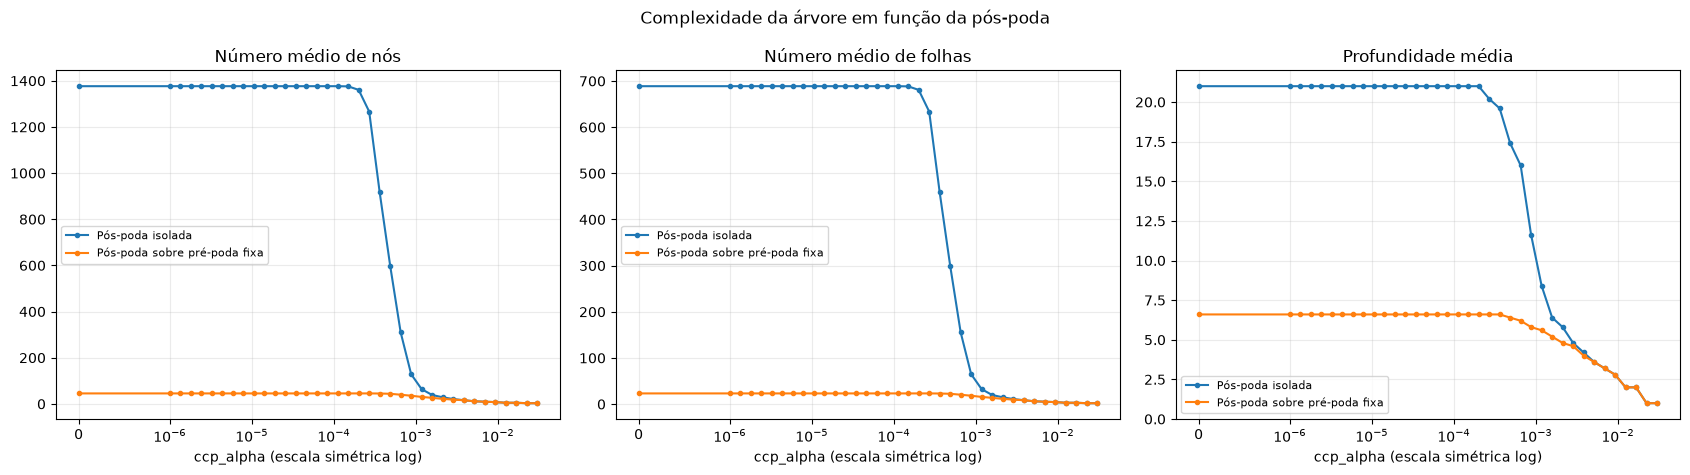

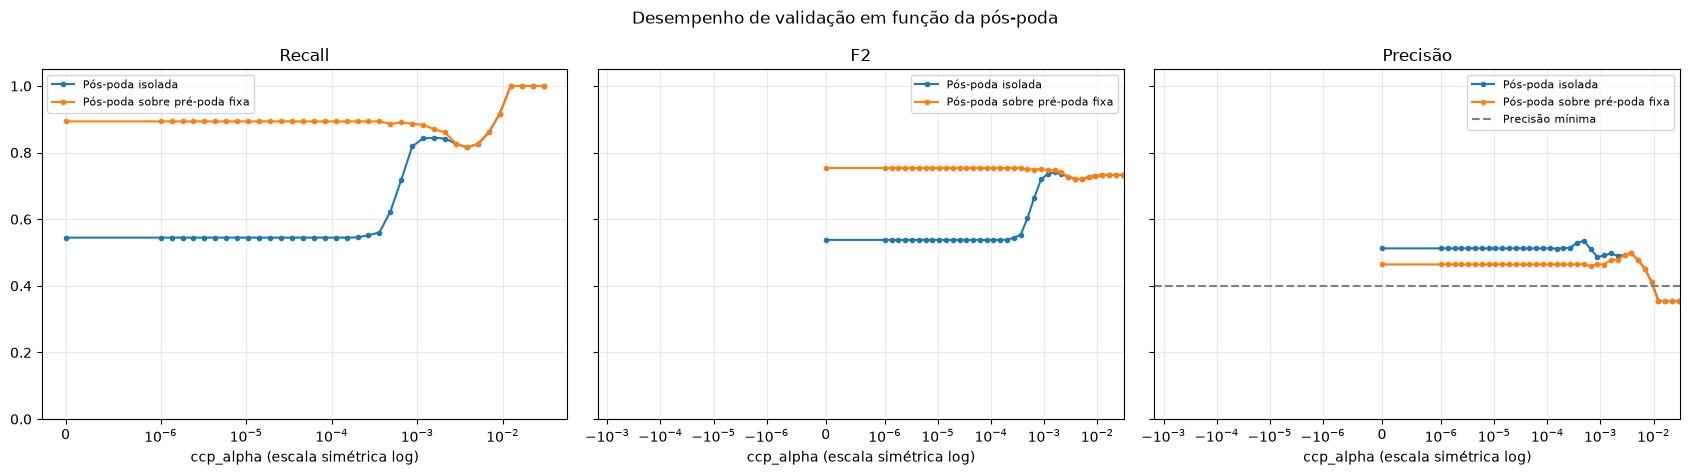

In [65]:
# Gráficos estruturais: nós, folhas e profundidade contra ccp_alpha.
fig, axs = plt.subplots(1, 3, figsize=(17, 4.8))
for cenario, parte in df_alpha_resumo.groupby('cenario', sort=False):
    parte = parte.sort_values('ccp_alpha')
    for ax, coluna, titulo in zip(
        axs, ['nos', 'folhas', 'profundidade'],
        ['Número médio de nós', 'Número médio de folhas', 'Profundidade média']
    ):
        ax.plot(parte['ccp_alpha'], parte[coluna], marker='.', label=cenario)
        ax.set_title(titulo)
for ax in axs:
    ax.set_xscale('symlog', linthresh=1e-6)
    ax.set_xlabel('ccp_alpha (escala simétrica log)')
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.suptitle('Complexidade da árvore em função da pós-poda')
plt.tight_layout()
plt.savefig(PASTA / 'alpha_nos_folhas_profundidade.png', dpi=200, bbox_inches='tight')
plt.show()

# Gráficos das métricas, para observar o custo/benefício de simplificar a árvore.
fig, axs = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
for cenario, parte in df_alpha_resumo.groupby('cenario', sort=False):
    parte = parte.sort_values('ccp_alpha')
    for ax, coluna, titulo in zip(
        axs, ['recall', 'f2', 'precisao'], ['Recall', 'F2', 'Precisão']
    ):
        ax.plot(parte['ccp_alpha'], parte[coluna], marker='.', label=cenario)
        ax.set_title(titulo)
for ax in axs:
    ax.set_xscale('symlog', linthresh=1e-6)
    ax.set_xlabel('ccp_alpha (escala simétrica log)')
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
axs[2].axhline(PRECISAO_MINIMA, ls='--', color='gray', label='Precisão mínima')
axs[2].legend(fontsize=8)
fig.suptitle('Desempenho de validação em função da pós-poda')
plt.tight_layout()
plt.savefig(PASTA / 'alpha_recall_f2_precisao.png', dpi=200, bbox_inches='tight')
plt.show()

**10. Congelar um candidato por estratégia antes do teste final**
Observe primeiro os gráficos e tabelas da segunda validação. Em ESCOLHA_FINAL, selecione um candidato por estratégia: aquele escolhido pelo melhor recall ou pelo melhor F2 na primeira CV. Essas escolhas podem ser apoiadas pelo diagnóstico da segunda CV; porém, nenhuma usa X_test/`y_test`.

Abaixo ficam inicialmente os candidatos por recall, para preservar a configuração da busca do notebook enviado. Troque a chave por _f2 caso deseje apresentar a alternativa correspondente no teste final.

In [66]:
ESCOLHA_FINAL = {
    'pre_poda': 'pre_poda_recall',    # ou 'pre_poda_f2'
    'pos_poda': 'pos_poda_recall',    # ou 'pos_poda_f2'
    'hibrida': 'hibrida_recall',      # ou 'hibrida_f2'
}

configuracoes = {'baseline': candidatos_duas_metricas['baseline']}
for estrategia, chave in ESCOLHA_FINAL.items():
    if chave not in candidatos_duas_metricas:
        print(f'{estrategia}: {chave!r} não elegível; não será avaliado no teste.')
        continue
    configuracoes[estrategia] = candidatos_duas_metricas[chave]

print('Configurações finais (escolhidas antes de avaliar no teste):')
for estrategia, config in configuracoes.items():
    nome = ESCOLHA_FINAL.get(estrategia, 'baseline')
    print(f'  {rotulo_modelo(nome)}')
with open(PASTA / 'configuracoes_congeladas.json', 'w', encoding='utf-8') as f:
    json.dump(configuracoes, f, indent=2, ensure_ascii=False)
with open(PASTA / 'selecoes_finais.json', 'w', encoding='utf-8') as f:
    json.dump(ESCOLHA_FINAL, f, indent=2, ensure_ascii=False)

Configurações finais (escolhidas antes de avaliar no teste):
  Baseline (sem poda) · Referência · limiar=0.20
  Pré-poda isolada · Melhor recall · limiar=0.20 · trial #64
  Pós-poda isolada · Melhor recall · limiar=0.20 · trial #52
  Poda híbrida (pré + pós) · Melhor recall · limiar=0.20 · trial #58


**11. Estabilidade dos candidatos finais na segunda validação**

Esta etapa não treina novamente os modelos: reutiliza os resultados por fold já obtidos na seção 8, evitando um terceiro ciclo de validação repetitivo. É um diagnóstico, não uma avaliação independente.

,modelo,recall_cv2,recall_dp,f2_cv2,f2_dp,precisao_cv2,precisao_dp,f1_cv2,acuracia_cv2,profundidade_media,folhas_medias,nos_medios,folds_com_precisao_minima,rotulo,limiar
0,baseline,0.5528,0.0604,0.5481,0.0525,0.5315,0.0243,0.5415,0.6696,22.4,710.0,1419.0,5,Baseline (sem poda) · Referência · limiar=0.20,0.2
2,hibrida_recall,0.9001,0.0211,0.7558,0.0118,0.4609,0.0111,0.6095,0.5911,6.8,27.2,53.4,5,Poda híbrida (pré + pós) · Melhor recall · lim...,0.2
4,pos_poda_recall,0.9274,0.0994,0.7236,0.0131,0.3977,0.0592,0.5505,0.4523,2.8,4.2,7.4,2,Pós-poda isolada · Melhor recall · limiar=0.20...,0.2
6,pre_poda_recall,0.9001,0.0211,0.7558,0.0118,0.4609,0.0111,0.6095,0.5911,6.8,27.2,53.4,5,Pré-poda isolada · Melhor recall · limiar=0.20...,0.2


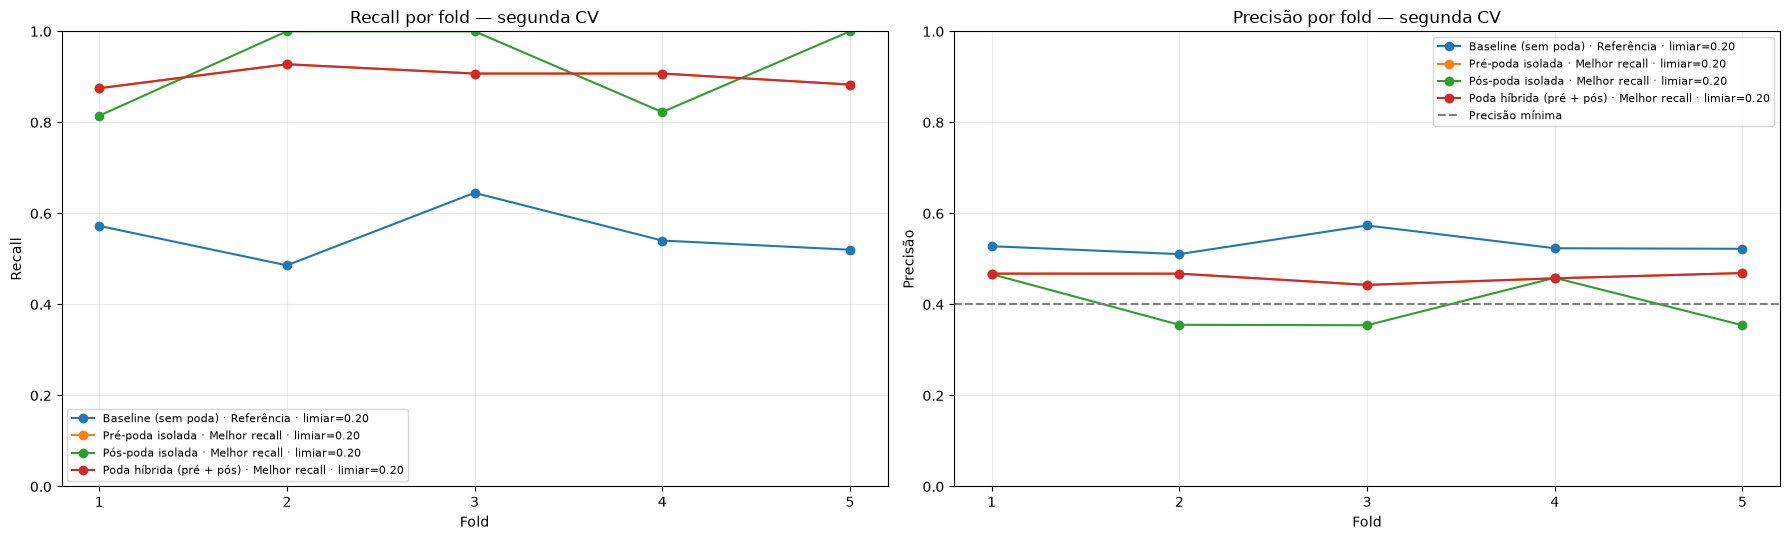

In [67]:
if 'df_cv2_folds' not in globals():
    df_cv2_folds = pd.read_csv(PASTA / 'segunda_validacao_por_fold.csv')
if 'df_cv2_resumo' not in globals():
    df_cv2_resumo = pd.read_csv(
        PASTA / 'comparacao_primeira_segunda_validacao.csv'
    )

nomes_escolhidos = ['baseline'] + [
    chave for chave in ESCOLHA_FINAL.values() if chave in candidatos_duas_metricas
]
df_folds = df_cv2_folds[df_cv2_folds['modelo'].isin(nomes_escolhidos)].copy()
df_estabilidade = df_cv2_resumo[df_cv2_resumo['modelo'].isin(nomes_escolhidos)].copy()
df_estabilidade['rotulo'] = df_estabilidade['modelo'].map(rotulo_modelo)
df_estabilidade['limiar'] = df_estabilidade['modelo'].map(
    lambda nome: float(candidatos_duas_metricas[nome]['limiar'])
)
display(df_estabilidade.round(4))

fig, axs = plt.subplots(1, 2, figsize=(18, 5.5))
for nome, grupo in df_folds.groupby('modelo', sort=False):
    axs[0].plot(grupo['fold'], grupo['recall'], marker='o', label=rotulo_modelo(nome, curto=True))
    axs[1].plot(grupo['fold'], grupo['precisao'], marker='o', label=rotulo_modelo(nome, curto=True))
axs[0].set(title='Recall por fold — segunda CV', xlabel='Fold', ylabel='Recall', ylim=(0, 1))
axs[1].set(title='Precisão por fold — segunda CV', xlabel='Fold', ylabel='Precisão', ylim=(0, 1))
axs[1].axhline(PRECISAO_MINIMA, linestyle='--', color='gray', label='Precisão mínima')
for ax in axs:
    ax.set_xticks(range(1, N_SPLITS + 1))
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(PASTA / 'estabilidade_candidatos_finais_cv2.png', dpi=200, bbox_inches='tight')
plt.show()

**12. Limiar de classificação (diagnóstico usando somente treino)**

A curva abaixo usa predições out-of-fold da melhor pré-poda. Como a própria escolha dos hiperparâmetros já usou estes folds, não é um teste independente. Para manter uma comparação isolada dos mecanismos de poda, não alteramos o limiar único LIMIAR com base nesta curva.

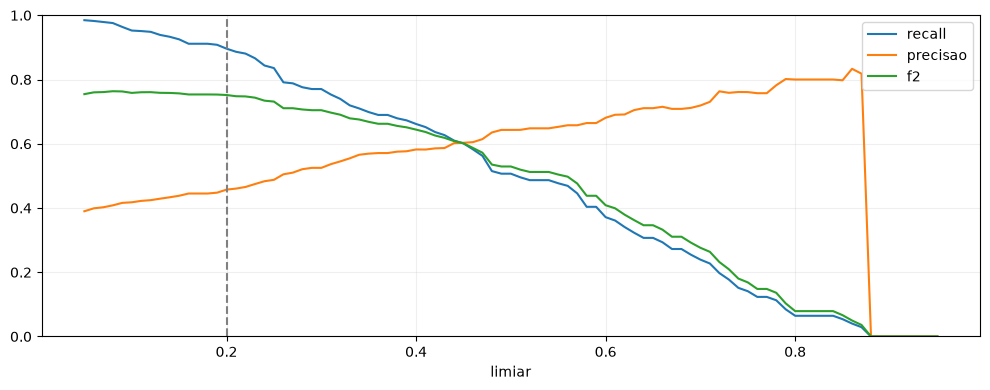

In [68]:
if 'pre_poda' in configuracoes:
    cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)
    modelo_pre = criar_pipeline(configuracoes['pre_poda']['parametros'])
    probabilidades_oof = cross_val_predict(
        modelo_pre, X_train, y_train, cv=cv, method='predict_proba'
    )[:, 1]
    linhas_threshold = []
    for thr in np.linspace(0.05, 0.95, 91):
        pred = (probabilidades_oof >= thr).astype(int)
        linhas_threshold.append({
            'limiar': thr,
            'recall': recall_score(y_train, pred, zero_division=0),
            'precisao': precision_score(y_train, pred, zero_division=0),
            'f2': fbeta_score(y_train, pred, beta=2, zero_division=0),
        })
    df_thresholds = pd.DataFrame(linhas_threshold)
    df_thresholds.to_csv(PASTA / 'curva_limiares_pre_poda.csv', index=False)
    ax = df_thresholds.plot(x='limiar', y=['recall', 'precisao', 'f2'], figsize=(10, 4))
    ax.axvline(LIMIAR, linestyle='--', color='gray', label='Limiar fixo')
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.savefig(PASTA / 'curva_limiares_pre_poda.png', dpi=200)
    plt.show()
else:
    print('Nenhum modelo pré-poda elegível: análise opcional ignorada.')

**13. Avaliação final nos 30% — executar uma vez após congelar modelos**

Esta etapa deve ser executada após a escolha dos parâmetros e do limiar com dados de treinamento. Não ajuste modelos por causa dos resultados abaixo. Como o teste foi consultado no histórico anterior, descreva essa limitação no relatório.

In [69]:
PASTA_FINAL = PASTA / 'avaliacao_final'
PASTA_FINAL.mkdir(parents=True, exist_ok=True)

modelos_treinados, predicoes_teste, historico_final = {}, {}, []
for nome, config in configuracoes.items():
    modelo = criar_pipeline(config['parametros'])
    modelo.fit(X_train, y_train)
    limiar = config['limiar']
    treino = metricas_para_limiar(modelo, X_train, y_train, limiar)
    teste = metricas_para_limiar(modelo, X_test, y_test, limiar)
    prob = modelo.predict_proba(X_test)[:, list(modelo.named_steps['arvore'].classes_).index(1)]
    pred = (prob >= limiar).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    arvore = modelo.named_steps['arvore']
    linha = {
        'modelo': nome,
        'rotulo': rotulo_modelo(ESCOLHA_FINAL.get(nome, 'baseline')),
        'limiar': limiar,
        'profundidade': arvore.get_depth(), 'folhas': arvore.get_n_leaves(),
        'roc_auc_teste': roc_auc_score(y_test, prob),
        'kappa_teste': cohen_kappa_score(y_test, pred),
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
    }
    for metrica in treino:
        linha[f'{metrica}_treino'] = treino[metrica]
        linha[f'{metrica}_teste'] = teste[metrica]
    linha['gap_recall'] = treino['recall'] - teste['recall']
    linha['gap_acuracia'] = treino['acuracia'] - teste['acuracia']
    historico_final.append(linha)
    modelos_treinados[nome] = modelo
    predicoes_teste[nome] = pred
    joblib.dump(modelo, PASTA_FINAL / f'{nome}.joblib')

df_final = pd.DataFrame(historico_final)
df_final.to_csv(PASTA_FINAL / 'metricas_finais.csv', index=False)
display(df_final[[
    'modelo', 'rotulo', 'limiar', 'recall_teste', 'precisao_teste',
    'f2_teste', 'acuracia_teste', 'gap_recall', 'profundidade', 'folhas'
]].round(4))

,modelo,rotulo,limiar,recall_teste,precisao_teste,f2_teste,acuracia_teste,gap_recall,profundidade,folhas
0,baseline,Baseline (sem poda) · Referência · limiar=0.20,0.2,0.5244,0.5274,0.5250,0.6651,0.4756,21,875
1,pre_poda,Pré-poda isolada · Melhor recall · limiar=0.20...,0.2,0.9060,0.4707,0.7646,0.6059,0.0247,7,35
2,pos_poda,Pós-poda isolada · Melhor recall · limiar=0.20...,0.2,1.0000,0.3542,0.7328,0.3542,0.0000,3,4
3,hibrida,Poda híbrida (pré + pós) · Melhor recall · lim...,0.2,0.9060,0.4707,0.7646,0.6059,0.0247,7,35


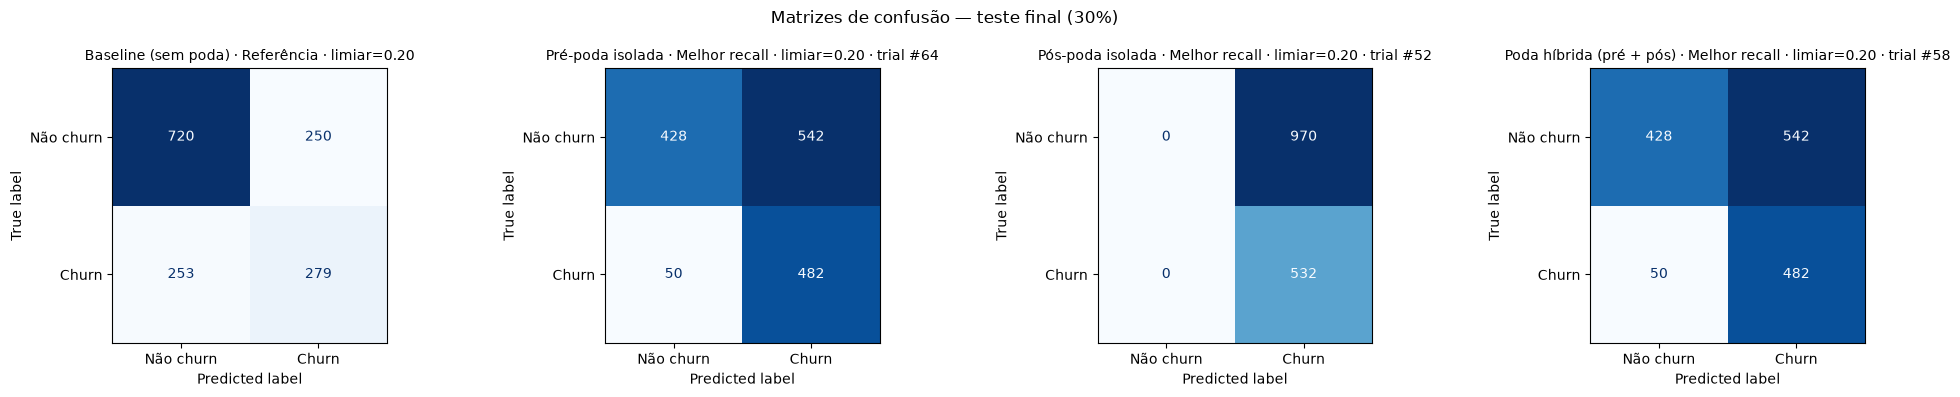

In [70]:
fig, axes = plt.subplots(1, len(predicoes_teste), figsize=(5*len(predicoes_teste), 4))
axes = np.atleast_1d(axes)
for ax, (nome, pred) in zip(axes, predicoes_teste.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, labels=[0, 1],
        display_labels=['Não churn', 'Churn'],
        values_format='d', cmap='Blues', colorbar=False, ax=ax
    )
    ax.set_title(rotulo_modelo(ESCOLHA_FINAL.get(nome, 'baseline')), fontsize=10)
plt.suptitle('Matrizes de confusão — teste final (30%)')
plt.tight_layout()
plt.savefig(PASTA_FINAL / 'matrizes_confusao.png', dpi=200)
plt.show()

**13.1. Matrizes dos melhores por recall e F2 no teste reservado (30%) — diagnóstico final**

Os dois melhores candidatos elegíveis foram definidos exclusivamente pela segunda CV dos 70% de treinamento na seção 8.1. Aqui treinamos essas configurações com os 70% completos e mostramos suas matrizes no conjunto de teste, sem alterar parâmetros ou limiares após olhar as respostas.

Se o melhor recall irrestrito prevê todos os clientes como churn, sua matriz também é incluída para diagnosticar o recall de 100%. Não utilize este teste para escolher novos candidatos, pois ele já deve ser considerado uma avaliação final, não uma etapa de otimização.

,modelo,rotulo,limiar,TN,FP,FN,TP,recall_oof,precisao_oof,f2_oof,acuracia_oof,percentual_previsto_churn
0,pos_poda_recall,Pós-poda isolada · Melhor recall · limiar=0.20...,0.2,0,970,0,532,1.000,0.3542,0.7328,0.3542,1.0000
1,pre_poda_f2,Pré-poda isolada · Melhor F2 · limiar=0.20 · t...,0.2,428,542,50,482,0.906,0.4707,0.7646,0.6059,0.6818


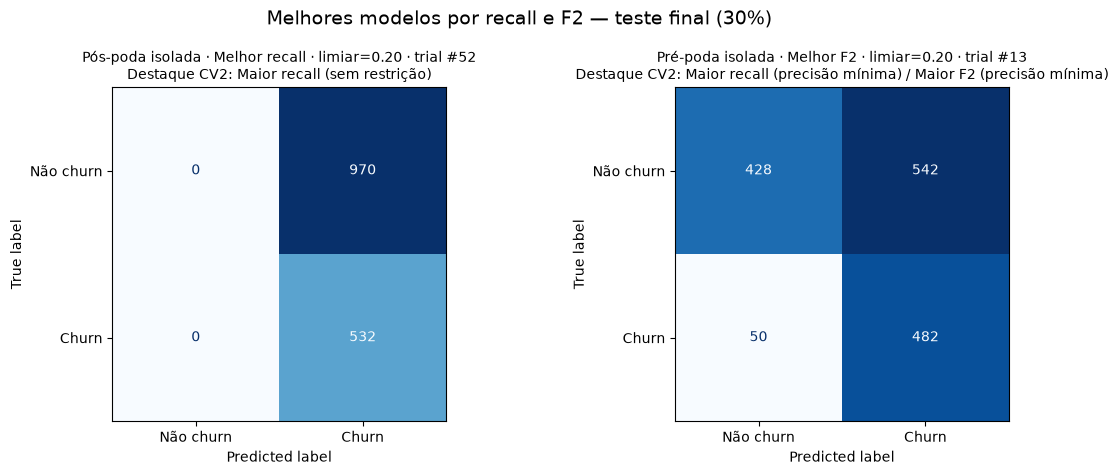

Os candidatos foram escolhidos antes desta avaliação, sem usar y_test.


In [71]:
# Só executar após a seção 8.1, com candidatos selecionados pelo treino.
if 'MODELOS_DESTAQUE_CV2' not in globals():
    raise RuntimeError('Execute primeiro a seção 8.1 para selecionar os candidatos.')

modelos_unicos = list(dict.fromkeys(MODELOS_DESTAQUE_CV2.values()))
linhas_teste_destaque = []
predicoes_teste_destaque = {}

for nome in modelos_unicos:
    # Não faz nova busca: reutiliza a configuração selecionada pelo Optuna.
    # Caso esse candidato já tenha sido ajustado na seção 13, reutiliza o modelo.
    nome_final = next(
        (nome_f for nome_f, nome_c in ESCOLHA_FINAL.items()
         if nome_c == nome and nome_f in modelos_treinados),
        None
    )
    if nome == 'baseline' and 'baseline' in modelos_treinados:
        nome_final = 'baseline'
    if nome_final is not None:
        modelo = modelos_treinados[nome_final]
    else:
        modelo = criar_pipeline(candidatos_duas_metricas[nome]['parametros'])
        modelo.fit(X_train, y_train)

    limiar = candidatos_duas_metricas[nome]['limiar']
    indice_churn = list(modelo.named_steps['arvore'].classes_).index(1)
    proba = modelo.predict_proba(X_test)[:, indice_churn]
    pred = (proba >= limiar).astype(int)
    predicoes_teste_destaque[nome] = pred
    linhas_teste_destaque.append(
        extrair_resumo_matriz(y_test, pred, nome)
    )

df_teste_destaque = pd.DataFrame(linhas_teste_destaque)
df_teste_destaque['rotulo'] = df_teste_destaque['modelo'].map(rotulo_modelo)
df_teste_destaque['limiar'] = df_teste_destaque['modelo'].map(
    lambda nome: float(candidatos_duas_metricas[nome]['limiar'])
)
df_teste_destaque.to_csv(PASTA_FINAL / 'melhores_recall_f2_metricas_teste.csv',
                        index=False)
cols_destaque = ['modelo', 'rotulo', 'limiar', 'TN', 'FP', 'FN', 'TP',
                 'recall_oof', 'precisao_oof', 'f2_oof', 'acuracia_oof',
                 'percentual_previsto_churn']
display(df_teste_destaque[cols_destaque].round(4))

fig, axes = plt.subplots(1, len(modelos_unicos),
                         figsize=(5.8 * len(modelos_unicos), 4.8))
axes = np.atleast_1d(axes)
for ax, nome in zip(axes, modelos_unicos):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicoes_teste_destaque[nome], labels=[0, 1],
        display_labels=['Não churn', 'Churn'],
        values_format='d', cmap='Blues', colorbar=False, ax=ax
    )
    ax.set_title(f'{rotulo_modelo(nome)}\nDestaque CV2: {legendas[nome]}', fontsize=10)
plt.suptitle('Melhores modelos por recall e F2 — teste final (30%)', fontsize=14)
plt.tight_layout()
plt.savefig(PASTA_FINAL / 'matrizes_melhores_recall_f2_teste.png',
            dpi=220, bbox_inches='tight')
plt.show()

print('Os candidatos foram escolhidos antes desta avaliação, sem usar y_test.')

**14. Importância de atributos e interpretação categórica**

In [72]:
for nome, modelo in modelos_treinados.items():
    arvore = modelo.named_steps['arvore']
    atributos = list(modelo.named_steps['preprocessamento'].get_feature_names_out())
    df_imp = pd.DataFrame({
        'atributo': atributos,
        'importancia': arvore.feature_importances_,
    }).sort_values('importancia', ascending=False)
    df_imp.to_csv(PASTA_FINAL / f'importancia_{nome}.csv', index=False)
    print(f'\n{nome} — importância dos atributos')
    display(df_imp.head(12))
    try:
        texto = export_text(arvore, feature_names=atributos, max_depth=4)
        (PASTA_FINAL / f'regras_parciais_{nome}.txt').write_text(texto, encoding='utf-8')
        print(texto)
    except Exception as exc:
        print('Exportação textual indisponível nesta build:', repr(exc))


baseline — importância dos atributos


,atributo,importancia
0,mensalidade_rs,0.326819
6,tempo_cliente_meses,0.221257
2,tipo_contrato,0.097304
1,atrasos_6m,0.073820
7,numero_chamados_total,0.066479
3,forma_pagamento,0.064239
9,numero_chamados_60_dias,0.040432
8,numero_chamados_30_dias,0.038150
10,numero_chamados_90_dias,0.035086
5,debito_automatico,0.022178


|--- tipo_contrato <= -inf
|   |--- tempo_cliente_meses <= 10.50
|   |   |--- mensalidade_rs <= 92.72
|   |   |   |--- tempo_cliente_meses <= 5.50
|   |   |   |   |--- mensalidade_rs <= 60.22
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- mensalidade_rs >  60.22
|   |   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- tempo_cliente_meses >  5.50
|   |   |   |   |--- atrasos_6m <= 2.50
|   |   |   |   |   |--- truncated branch of depth 9
|   |   |   |   |--- atrasos_6m >  2.50
|   |   |   |   |   |--- class: 1
|   |   |--- mensalidade_rs >  92.72
|   |   |   |--- atrasos_6m <= 0.50
|   |   |   |   |--- tempo_cliente_meses <= 6.50
|   |   |   |   |   |--- truncated branch of depth 4
|   |   |   |   |--- tempo_cliente_meses >  6.50
|   |   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- atrasos_6m >  0.50
|   |   |   |   |--- debito_automatico <= 0.50
|   |   |   |   |   |--- truncated branch of depth 4
|   |   |   |   |--- debito_automatico >  0.50
|   

,atributo,importancia
6,tempo_cliente_meses,0.366281
2,tipo_contrato,0.297655
7,numero_chamados_total,0.091919
0,mensalidade_rs,0.091484
10,numero_chamados_90_dias,0.072763
1,atrasos_6m,0.037218
4,fibra_optica,0.026436
3,forma_pagamento,0.010849
5,debito_automatico,0.004772
8,numero_chamados_30_dias,0.000622


|--- tipo_contrato <= -inf
|   |--- tempo_cliente_meses <= 10.50
|   |   |--- mensalidade_rs <= 92.72
|   |   |   |--- class: 0
|   |   |--- mensalidade_rs >  92.72
|   |   |   |--- class: 1
|   |--- tempo_cliente_meses >  10.50
|   |   |--- numero_chamados_90_dias <= 2.50
|   |   |   |--- tempo_cliente_meses <= 21.50
|   |   |   |   |--- fibra_optica <= 0.50
|   |   |   |   |   |--- truncated branch of depth 2
|   |   |   |   |--- fibra_optica >  0.50
|   |   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- tempo_cliente_meses >  21.50
|   |   |   |   |--- tempo_cliente_meses <= 33.50
|   |   |   |   |   |--- truncated branch of depth 3
|   |   |   |   |--- tempo_cliente_meses >  33.50
|   |   |   |   |   |--- truncated branch of depth 3
|   |   |--- numero_chamados_90_dias >  2.50
|   |   |   |--- tempo_cliente_meses <= 27.50
|   |   |   |   |--- mensalidade_rs <= 86.08
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- mensalidade_rs >  86.08
|   |   |   |   |   |--

,atributo,importancia
2,tipo_contrato,0.522416
6,tempo_cliente_meses,0.315357
7,numero_chamados_total,0.162227
1,atrasos_6m,0.000000
0,mensalidade_rs,0.000000
4,fibra_optica,0.000000
3,forma_pagamento,0.000000
5,debito_automatico,0.000000
8,numero_chamados_30_dias,0.000000
9,numero_chamados_60_dias,0.000000


|--- tipo_contrato <= -inf
|   |--- class: 0
|--- tipo_contrato >  -inf
|   |--- tempo_cliente_meses <= 30.50
|   |   |--- numero_chamados_total <= 2.50
|   |   |   |--- class: 0
|   |   |--- numero_chamados_total >  2.50
|   |   |   |--- class: 1
|   |--- tempo_cliente_meses >  30.50
|   |   |--- class: 0


hibrida — importância dos atributos


,atributo,importancia
6,tempo_cliente_meses,0.366439
2,tipo_contrato,0.297655
10,numero_chamados_90_dias,0.128834
0,mensalidade_rs,0.091327
1,atrasos_6m,0.037218
7,numero_chamados_total,0.035848
4,fibra_optica,0.026436
3,forma_pagamento,0.010849
5,debito_automatico,0.004772
8,numero_chamados_30_dias,0.000622


|--- tipo_contrato <= -inf
|   |--- tempo_cliente_meses <= 10.50
|   |   |--- mensalidade_rs <= 92.72
|   |   |   |--- class: 0
|   |   |--- mensalidade_rs >  92.72
|   |   |   |--- class: 1
|   |--- tempo_cliente_meses >  10.50
|   |   |--- numero_chamados_90_dias <= 2.50
|   |   |   |--- tempo_cliente_meses <= 21.50
|   |   |   |   |--- fibra_optica <= 0.50
|   |   |   |   |   |--- truncated branch of depth 2
|   |   |   |   |--- fibra_optica >  0.50
|   |   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- tempo_cliente_meses >  21.50
|   |   |   |   |--- tempo_cliente_meses <= 33.50
|   |   |   |   |   |--- truncated branch of depth 3
|   |   |   |   |--- tempo_cliente_meses >  33.50
|   |   |   |   |   |--- truncated branch of depth 3
|   |   |--- numero_chamados_90_dias >  2.50
|   |   |   |--- tempo_cliente_meses <= 27.50
|   |   |   |   |--- mensalidade_rs <= 86.08
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- mensalidade_rs >  86.08
|   |   |   |   |   |--

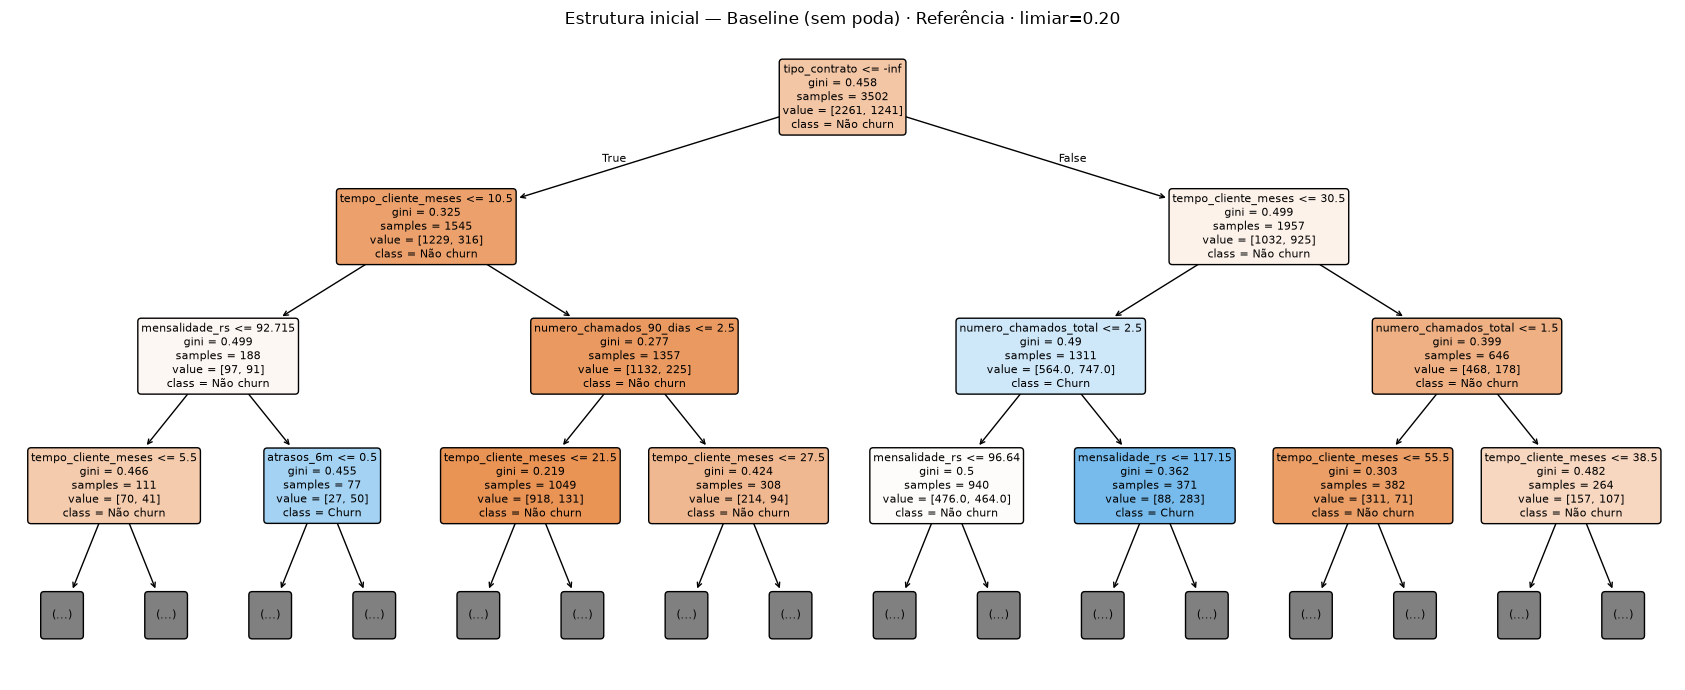

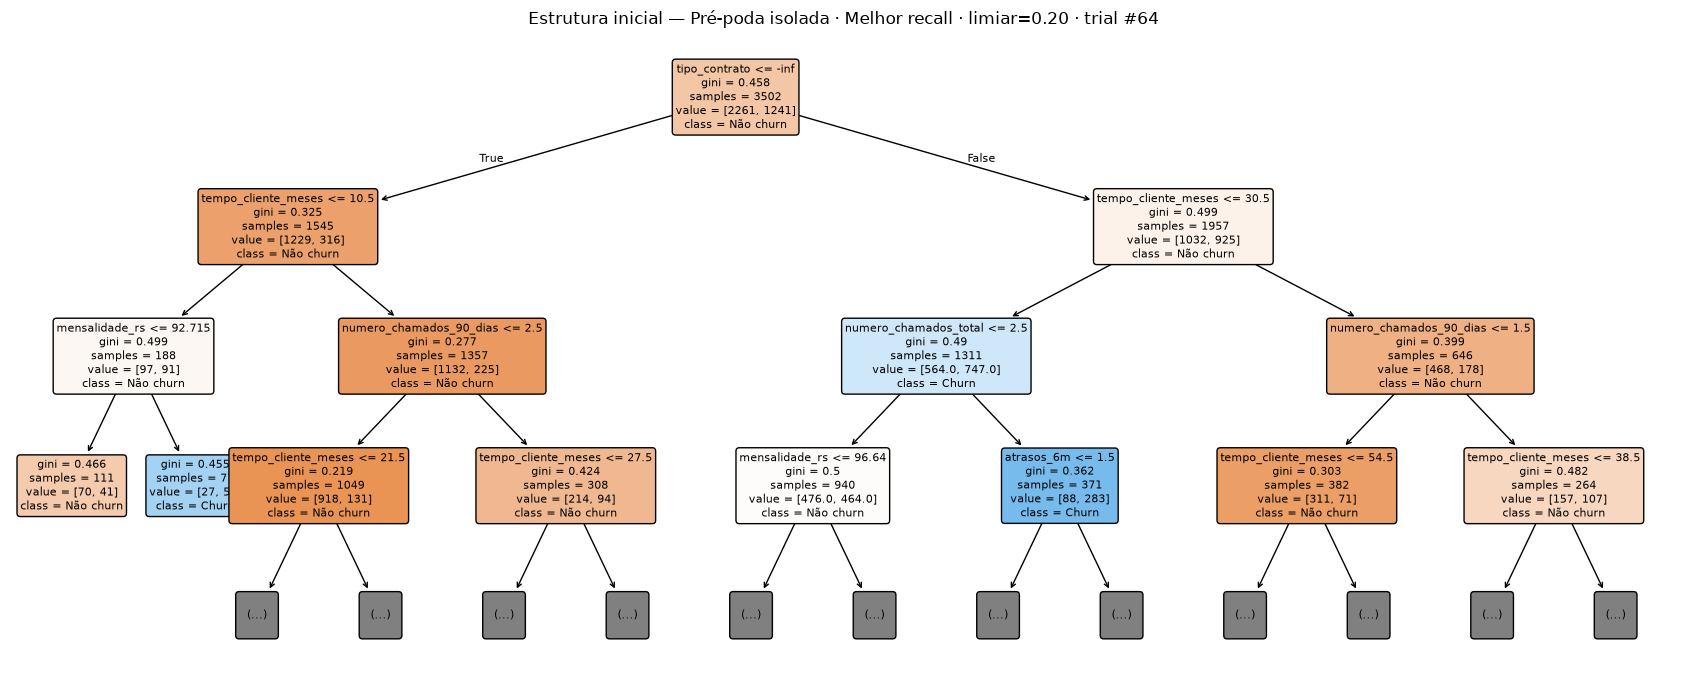

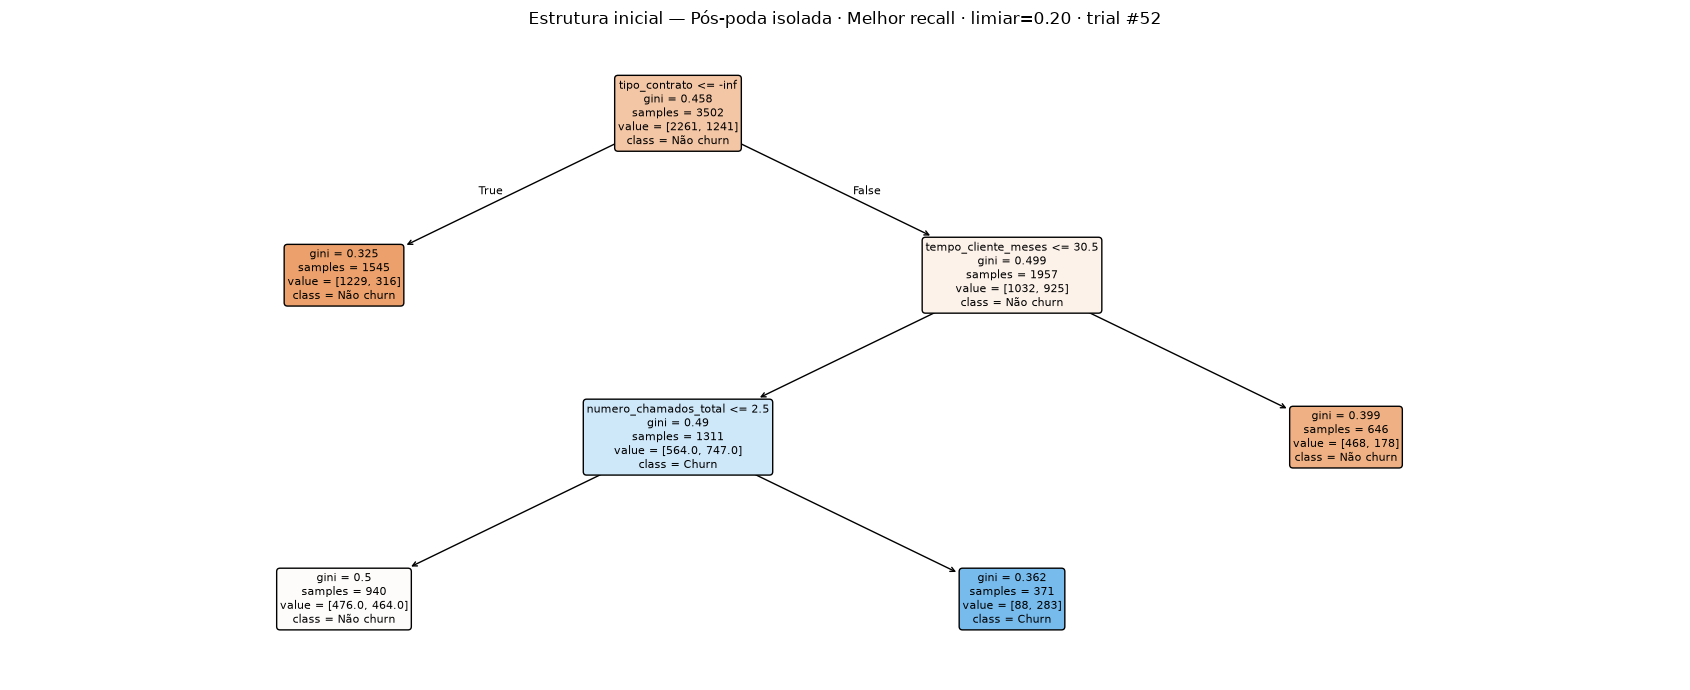

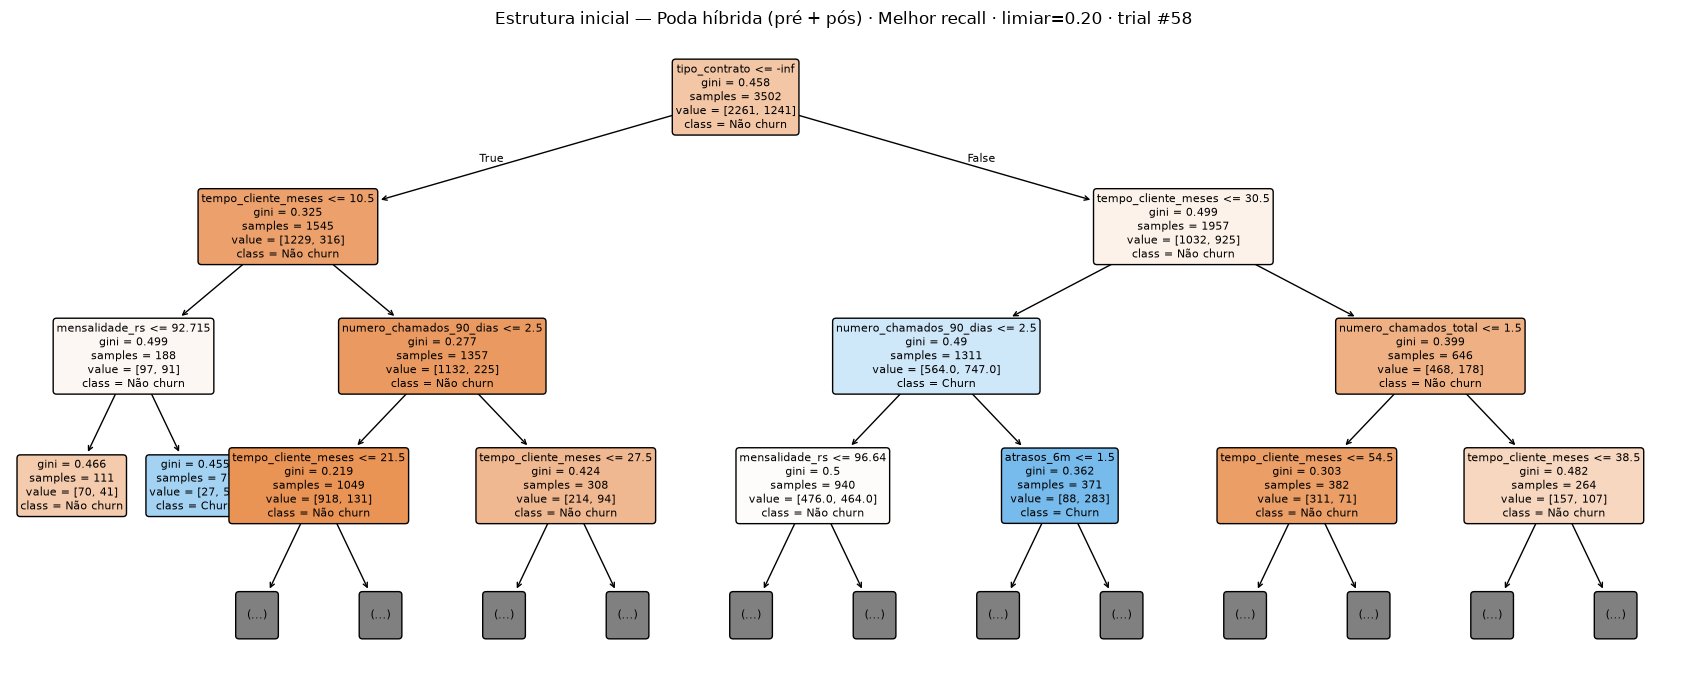

In [73]:
# Visualização de até 3 níveis (o restante pode ser muito grande)
for nome, modelo in modelos_treinados.items():
    arvore = modelo.named_steps['arvore']
    atributos = list(modelo.named_steps['preprocessamento'].get_feature_names_out())
    try:
        plt.figure(figsize=(17, 7))
        plot_tree(
            arvore, feature_names=atributos,
            class_names=['Não churn', 'Churn'],
            max_depth=3, filled=True, rounded=True, fontsize=8,
        )
        plt.title(f'Estrutura inicial — {rotulo_modelo(ESCOLHA_FINAL.get(nome, "baseline"))}')
        plt.tight_layout()
        plt.savefig(PASTA_FINAL / f'arvore_{nome}.png', dpi=200, bbox_inches='tight')
        plt.show()
    except Exception as exc:
        plt.close()
        print(f'{nome}: visualização indisponível nesta build:', repr(exc))

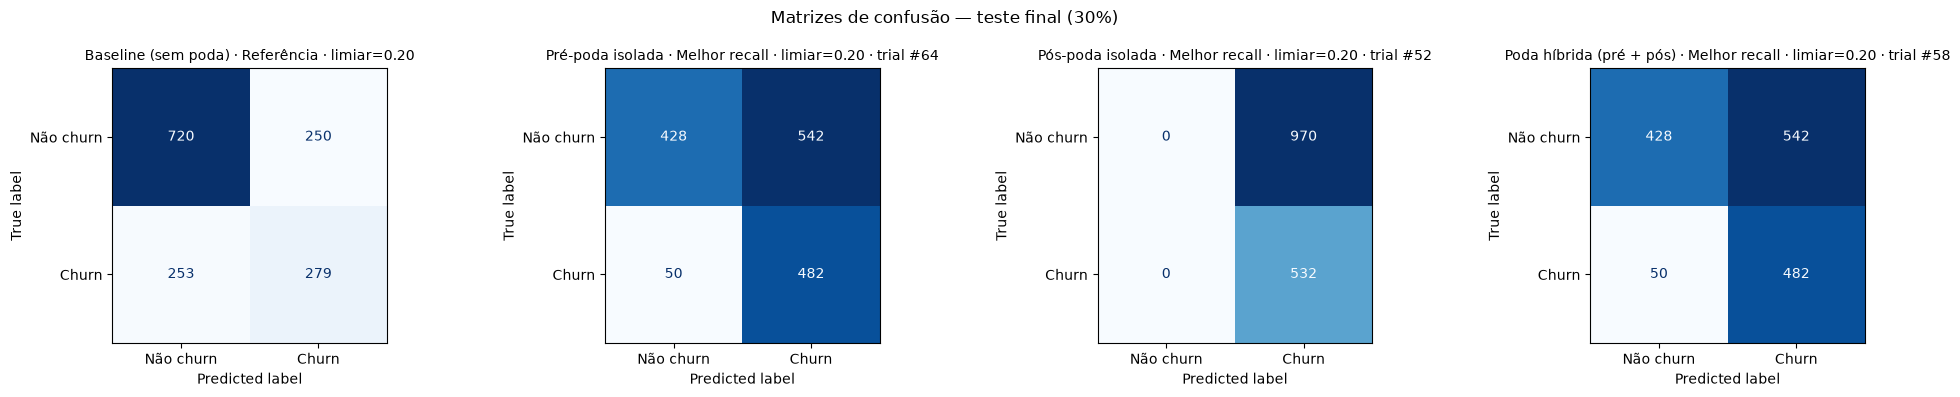

In [74]:
fig, axes = plt.subplots(1, len(predicoes_teste), figsize=(5*len(predicoes_teste), 4))
axes = np.atleast_1d(axes)
for ax, (nome, pred) in zip(axes, predicoes_teste.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, labels=[0, 1],
        display_labels=['Não churn', 'Churn'],
        values_format='d', cmap='Blues', colorbar=False, ax=ax
    )
    ax.set_title(rotulo_modelo(ESCOLHA_FINAL.get(nome, 'baseline')), fontsize=10)
plt.suptitle('Matrizes de confusão — teste final (30%)')
plt.tight_layout()
plt.savefig(PASTA_FINAL / 'matrizes_confusao.png', dpi=200)
plt.show()